# Drug-Quality Recall Intelligence for Pharmaceutical Procurement
### Early detection of abnormal drug-quality recall patterns using openFDA data: an MSc capstone prototype

**In one sentence:** this notebook turns 14 years of US FDA drug-recall records into evidence that a Kenyan buyer (KEMSA, MEDS, a hospital pharmacy or the Pharmacy and Poisons Board) can query in plain English before awarding a tender.

**What the system does**

| Step | Component ("specialist") | Its single job |
|---|---|---|
| 1 | Data pipeline + SQL database | Clean, traceable recall records; exact counts |
| 2 | **Recall-reason classifier** (TF-IDF + Logistic Regression) | Read free-text recall reasons and name the quality failure |
| 3 | **Anomaly detectors** (rolling z-score, IQR, Isolation Forest) | Spot unusual surges by failure type, dosage form and firm |
| 4 | **Backtest** on 6 real crises | Check honestly whether the detectors would have worked |
| 5 | **Supplier evidence + tender screening** | One-page evidence brief per bidder |
| 6 | **AI assistant** (search model + Claude LLM + code checker) | Answer stakeholder questions in plain English, with citations |

**Ground rules (decision support, not decision making)**
* The tool **never** declares a medicine unsafe or tells anyone to accept or reject a supplier. It gives **evidence and questions to ask**; people decide.
* It runs in **historical research mode**: one fixed, fingerprinted snapshot of openFDA data, with **no** internet data downloads during the analysis.
* Every number in the conclusions is **printed by code**, never typed by hand, so the text always matches the results.

**Files needed**

| File | What it is |
|---|---|
| `data/drug_recalls.csv` | openFDA Drug Enforcement snapshot |
| `data/labelled_recall_reasons.csv` | 1,000 labelled recall reasons |

**How to run:** *Kernel → Restart & Run All* (about 5 minutes). For live AI answers, set the environment variable `ANTHROPIC_API_KEY` **before** starting Jupyter (see Section 8).

## Section 1. Setup, data loading and provenance

### 1.1 Libraries and settings
**What:** we load the Python toolboxes (libraries) and fix all the settings in one place.

**Why:** keeping the settings together makes the analysis easy to audit. A panelist can see every threshold we chose *before* looking at the results.

| Library | Job |
|---|---|
| `pandas`, `numpy` | Tables and maths |
| `matplotlib` | Charts |
| `sqlite3` | A small SQL database stored in a single file |
| `scikit-learn` | Machine learning (TF-IDF, logistic regression, Isolation Forest, metrics) |
| `joblib` | Saving trained models so they can be reused |

`RANDOM_STATE = 42` fixes the random choices (sampling, model training), so every run gives identical results. This is called **reproducibility**.

In [1]:
import os, re, json, hashlib, sqlite3, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib


from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix, cohen_kappa_score
from sklearn.ensemble import IsolationForest
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 180)

# ---- files and folders ----
DATA_FILE   = Path("drug_recalls.csv")
LABELS_FILE = Path("labelled_recall_reasons.csv")
OUT = Path("outputs")
for sub in ["", "figures", "models", "tableau", "tender_briefs", "vector_db"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# ---- all analysis settings in one place (fixed BEFORE looking at back-test results) ----
RANDOM_STATE      = 42
BASELINE_MONTHS   = 12     # look-back window for "normal" behaviour
Z_THRESHOLD       = 3.0    # rolling z-score alert level
STD_FLOOR         = 1.0    # minimum spread, so a quiet series cannot alert on a single recall
IQR_K             = 1.5    # Tukey fence: Q3 + 1.5 x IQR
MIN_EVENTS        = 3      # a month needs at least 3 recall events before any alert
IF_TOP_SHARE      = 0.01   # Isolation Forest: flag the most unusual 1% of training months
KEPT_ACCURACY_GOAL = 0.95  # classifier: predictions we keep must be at least 95% correct

np.random.seed(RANDOM_STATE)
print("Setup complete.")

Setup complete.


### 1.2 Load the snapshot and record its fingerprint
**What:** we read the recall file and record exactly *which* data was used.

**Why:** a regulator must be able to reproduce our results.
* The **SHA-256 hash** is a fingerprint of the file. If one character changes, the fingerprint changes.
* We also record the date range and the number of records.
* The original download date was not recorded, so the **latest FDA report date** in the file is used as the effective snapshot date.

**Resilience:** the code stops with a clear message if the file is missing or an essential column is absent, rather than failing confusingly later.

In [2]:
assert DATA_FILE.exists(), f"Missing {DATA_FILE} - see README"
raw = pd.read_csv(DATA_FILE, low_memory=False, dtype={"recall_number": str, "postal_code": str})
ESSENTIAL = ["recall_number", "event_id", "classification", "reason_for_recall", "product_description",
             "recalling_firm", "recall_initiation_date", "report_date", "country"]
missing = [c for c in ESSENTIAL if c not in raw.columns]
assert not missing, f"Essential columns missing: {missing}"

def to_date(series):
    # openFDA stores dates as numbers like 20190315 -> real dates (invalid values become NaT = missing)
    return pd.to_datetime(pd.to_numeric(series, errors="coerce").astype("Int64").astype(str), format="%Y%m%d", errors="coerce")

provenance = {
    "source": "openFDA Drug Enforcement Reports (https://open.fda.gov/apis/drug/enforcement/)",
    "sha256": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    "records": len(raw), "events": int(raw.event_id.nunique()),
    "report_date_range": [str(to_date(raw.report_date).min().date()), str(to_date(raw.report_date).max().date())],
    "effective_snapshot_date": str(to_date(raw.report_date).max().date()),
    "mode": "Historical research mode - no API calls during analysis",
}
(OUT / "snapshot_provenance.json").write_text(json.dumps(provenance, indent=2))
print(json.dumps(provenance, indent=2))

{
  "source": "openFDA Drug Enforcement Reports (https://open.fda.gov/apis/drug/enforcement/)",
  "sha256": "084964e13f5841e6822110d7f5b1409f8029bc0ab3b86b4089d60c021bae5c91",
  "records": 18010,
  "events": 4705,
  "report_date_range": [
    "2012-06-20",
    "2026-10-07"
  ],
  "effective_snapshot_date": "2026-10-07",
  "mode": "Historical research mode - no API calls during analysis"
}


## Section 2. Cleaning, standardising and building the SQL database

### 2.1 Cleaning steps
1. **Dates** are converted to real dates. We keep two of them:
   * `initiation_date`: when the firm started the recall.
   * `report_date`: when FDA **published** it. This is the date outsiders could first know about it.
2. **Text** in recall reasons is tidied (broken characters and extra spaces removed).
3. **Missing IDs:** two rows have no `recall_number`. They are kept, with a clearly labelled surrogate ID, never deleted silently.
4. **Firm names:** "Teva Pharmaceuticals USA, Inc." and "Teva Pharmaceuticals USA Inc" are the same firm written differently. We create a standardised name **next to** the original:
   * Lowercase, remove punctuation, remove legal suffixes such as Inc, LLC, Ltd.
   * We **never** fuzzy-match. "Teva Pharmaceuticals" and "Teva Pharmaceuticals USA" stay separate, because they may be different legal entities.
   * Every mapping is saved, so it can be checked.
5. **Product group** (dosage form) is derived from keywords in the product description, because the route field is about 83% empty. The rules are printed in the code.

**Important pharmaceutical point:** the *recalling firm* is often a repackager, distributor or compounding pharmacy, **not** the manufacturer. We never infer a manufacturing site or country from a name.

In [3]:
df = raw.copy()
df["initiation_date"] = to_date(df.recall_initiation_date)
df["report_date_dt"]  = to_date(df.report_date)
df["reason_clean"] = (df.reason_for_recall.fillna("").str.replace("¿", " ", regex=False)
                      .str.replace(r"\s+", " ", regex=True).str.strip())
df["report_month"] = df.report_date_dt.dt.to_period("M")
df["initiation_month"] = df.initiation_date.dt.to_period("M")
df["is_class_I"] = df.classification.eq("Class I")

# Missing recall numbers -> traceable surrogate IDs (kept, never deleted)
df["id_is_surrogate"] = df.recall_number.isna()
df.loc[df.id_is_surrogate, "recall_number"] = ["MISSING-" + str(e) + "-" + str(i) for i, e in
                                                df.loc[df.id_is_surrogate, "event_id"].items()]

LEGAL_SUFFIXES = {"inc", "incorporated", "llc", "ltd", "limited", "corp", "corporation", "co", "company",
                  "lp", "llp", "plc", "pvt", "private", "gmbh", "sa", "ag", "bv"}
def standardise_firm(name):
    words = re.sub(r"[^a-z0-9 ]", " ", str(name).lower().replace("&", " and ")).split()
    words = [w for w in words if w not in LEGAL_SUFFIXES]
    return " ".join(words) if words else str(name).lower()

df["firm_std"] = df.recalling_firm.map(standardise_firm)
firm_map = df.groupby(["firm_std", "recalling_firm"]).size().reset_index(name="records")
firm_map.to_csv(OUT / "firm_name_mapping.csv", index=False)

PRODUCT_GROUP_RULES = [   # first match wins
    ("Ophthalmic",   r"ophthalm|eye drop|eye wash|eyewash|lubricant eye|artificial tears"),
    ("Injectable",   r"inject|\binj\b|intravenous|\biv\b|syringe|\bvial|infusion|\bmdv\b|\bsdv\b|intrathecal"),
    ("Inhalation",   r"inhal|nebuli|aerosol"),
    ("Nasal/Otic",   r"nasal|\botic\b|\bear\b"),
    ("Topical",      r"cream|ointment|\bgel\b|lotion|topical|sanitizer|transdermal|patch|shampoo|sunscreen|spf"),
    ("Oral solid",   r"tablet|capsule|caplet|\btab\b|\bcap\b|lozenge|softgel"),
    ("Oral liquid",  r"oral solution|suspension|syrup|elixir|oral liquid|drops|solution"),
]
def product_group(text):
    t = str(text).lower()
    return next((g for g, pat in PRODUCT_GROUP_RULES if re.search(pat, t)), "Other/unspecified")
df["product_group"] = df.product_description.map(product_group)

print(f"Firm spellings: {df.recalling_firm.nunique()} -> standardised names: {df.firm_std.nunique()}")
print(df.product_group.value_counts().to_string())

Firm spellings: 1667 -> standardised names: 1468
product_group
Injectable           6245
Oral solid           4545
Other/unspecified    3769
Topical              1328
Oral liquid          1076
Ophthalmic            689
Nasal/Otic            240
Inhalation            118


### 2.2 Automated checks on the cleaning
An `assert` stops the notebook if something is wrong, like an in-process quality check on a production line.

In [4]:
assert len(df) == len(raw), "No rows may be lost"
assert df.recall_number.is_unique, "Recall IDs must be unique"
assert df.report_date_dt.notna().all(), "Every record needs a publication date"
assert df.duplicated(subset=[c for c in raw.columns]).sum() == 0, "Unexpected exact duplicates"
print("Cleaning checks passed:", len(df), "records,", df.event_id.nunique(), "events,", int(df.id_is_surrogate.sum()), "surrogate IDs")

Cleaning checks passed: 18010 records, 4705 events, 2 surrogate IDs


### 2.3 The SQL database
**What:** we save the clean table into `outputs/recalls.db` (SQLite) and write a helper `run_sql()` for asking questions in SQL.

**Why SQL?** Exact questions ("how many Class I recalls did firm X have in 2023?") need exact answers. Later, the AI assistant gets all its numbers from these SQL queries, because language models are unreliable at counting.

**Key SQL words:**
* `SELECT`: choose the columns.
* `WHERE`: filter the rows.
* `GROUP BY`: form groups.
* `COUNT(DISTINCT event_id)`: count unique recall events.
* `ORDER BY ... DESC`: sort from largest to smallest.

In [5]:
con = sqlite3.connect(OUT / "recalls.db")
sql_cols = ["recall_number", "event_id", "classification", "status", "reason_clean", "product_description",
            "recalling_firm", "firm_std", "country", "product_group", "distribution_pattern"]
tbl = df[sql_cols].copy()
tbl["report_date"] = df.report_date_dt.dt.strftime("%Y-%m-%d")
tbl["initiation_date"] = df.initiation_date.dt.strftime("%Y-%m-%d")
tbl.to_sql("recalls", con, if_exists="replace", index=False)

def run_sql(query, params=()):
    return pd.read_sql_query(query, con, params=params)

run_sql('''SELECT firm_std, COUNT(DISTINCT event_id) AS events, SUM(classification='Class I') AS class_I_records
           FROM recalls GROUP BY firm_std ORDER BY events DESC LIMIT 8''')

,firm_std,events,class_I_records
0,teva pharmaceuticals usa,158,6
1,hospira,109,35
2,sun pharmaceutical industries,95,3
3,lupin pharmaceuticals,91,5
4,dr reddy s laboratories,88,5
5,pfizer,75,17
6,baxter healthcare,68,30
7,akorn,65,0


## Section 3. Exploratory analysis: what the data can and cannot tell us

> **What one row means.**
> * Each row is **one recalled product**, with its own `recall_number`.
> * Products recalled together for the same problem share an `event_id`. For example, a pharmacy recalling 400 compounded products creates **1 event and 400 rows**.
> * The firm on the row is the firm that **did the recall**. That may be the manufacturer, but it may also be a repackager, distributor or pharmacy.

We check three things that shape every later decision:
1. **Rows vs events.** One recall *event* can contain hundreds of product rows (a compounding pharmacy recalling everything it made). Counting rows would make that look like a huge surge, so **we count events**.
2. **Volume over time.**
3. **Reporting lag:** the time between a firm starting a recall and FDA publishing it. This is the hard limit on how "early" any warning based on FDA data can be.

Events: 4,705 | rows: 18,010 | rows per event: median 1, max 470
Reporting lag (recall start -> FDA publication): median 47 days, 90th percentile 197 days
classification
Class II              14542
Class I                1750
Class III              1716
Not Yet Classified        2


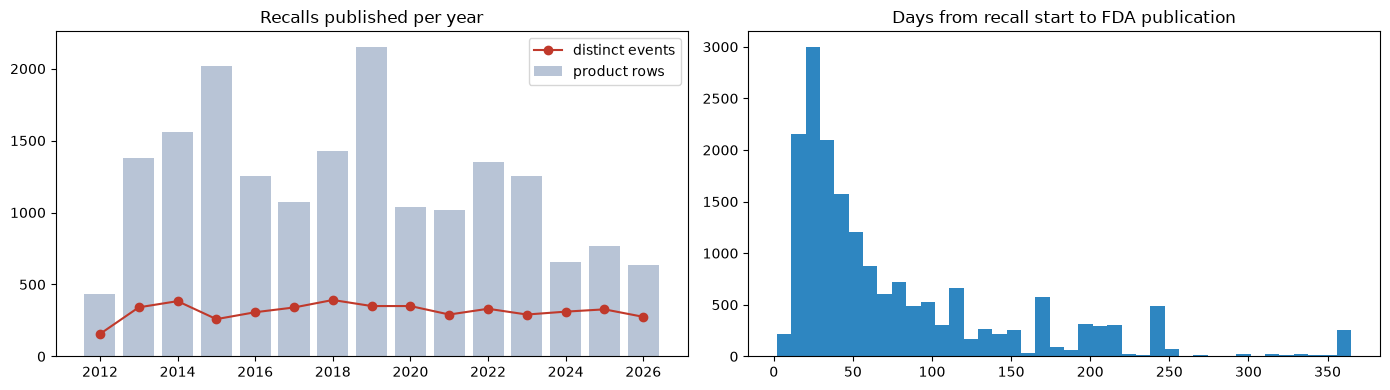

In [6]:
rows_per_event = df.groupby("event_id").size()
lag_days = (df.report_date_dt - df.initiation_date).dt.days
print(f"Events: {df.event_id.nunique():,} | rows: {len(df):,} | rows per event: median {rows_per_event.median():.0f}, max {rows_per_event.max()}")
print(f"Reporting lag (recall start -> FDA publication): median {lag_days.median():.0f} days, 90th percentile {lag_days.quantile(.9):.0f} days")
print(df.classification.value_counts().to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
yearly = df.groupby(df.report_date_dt.dt.year).agg(rows=("recall_number", "size"), events=("event_id", "nunique"))
ax[0].bar(yearly.index, yearly.rows, color="#b8c4d6", label="product rows")
ax[0].plot(yearly.index, yearly.events, "o-", color="#c0392b", label="distinct events")
ax[0].set_title("Recalls published per year"); ax[0].legend()
ax[1].hist(lag_days.clip(0, 365), bins=40, color="#2e86c1"); ax[1].set_title("Days from recall start to FDA publication")
plt.tight_layout(); plt.savefig(OUT / "figures/eda.png", dpi=110); plt.show()

**How to read this:**
* Grey bars far above the red line mean a few firms recalled many products at once. That is why we count events.
* The median lag of about **7 weeks** means FDA data shows a recall only after it has started. This system can therefore offer **systematic and timely recognition**, not advance prediction. Section 6 tests exactly this.
* 2012 and 2026 are partial years.

## Section 4. Classifying recall reasons (NLP)

### 4.1 The labelled data and how it was made
Recall reasons are free text written in many different ways. The same failure can appear as *"CGMP Deviations: presence of NDMA"*, *"carcinogen impurity detected in API"* or *"Failed Impurities/Degradation Specifications"*. We need a consistent **category** for every recall.

**Training labels:**
* 1,000 (event, reason) pairs were drawn at random (seed 42).
* They were labelled with a written **10-category codebook** by **LLM-assisted annotation (Claude)**.
* The team then verified them:
  * A blind check of 150 records gives a human–AI agreement score (kappa).
  * Low-confidence and disputed labels were reviewed.
* Any human correction in the column `human_verified_label` **overrides** the AI label.

The cell below reports how many labels have been human-verified, so the status is always visible.

| Category | Meaning |
|---|---|
| CONTAMINATION_STERILITY | Microbes, mould, non-sterility, lack of sterility assurance |
| IMPURITIES | Impurities or degradants, nitrosamines (NDMA…), benzene, methanol, cross-contamination |
| POTENCY_STRENGTH | Too little or too much active ingredient |
| DISSOLUTION | Tablet or capsule does not release the drug properly |
| CGMP_DEVIATION | Quality-system failure with no specific product defect stated |
| LABELING_PACKAGING | Label mix-ups, wrong tablets in the bottle, defective containers or devices |
| STABILITY | Degradation over shelf life, temperature abuse, discolouration |
| FOREIGN_MATTER | Particles, glass, metal, hair |
| UNAPPROVED_UNDECLARED | Unapproved drugs, hidden ingredients (e.g. sildenafil in "supplements") |
| OTHER | Tablet defects, pH, viscosity, formulation errors |

In [7]:
labels = pd.read_csv(LABELS_FILE)
CATEGORIES = ["CONTAMINATION_STERILITY", "IMPURITIES", "POTENCY_STRENGTH", "DISSOLUTION", "CGMP_DEVIATION",
              "LABELING_PACKAGING", "STABILITY", "FOREIGN_MATTER", "UNAPPROVED_UNDECLARED", "OTHER"]
human = labels.get("human_verified_label", pd.Series(index=labels.index, dtype=object))
has_human = human.notna() & human.astype(str).str.strip().ne("") & human.astype(str).ne("nan")
labels["final_label"] = np.where(has_human, human, labels.label)
labels["label_source"] = np.where(has_human, "human-verified", "AI-assisted (Claude)")
assert set(labels.final_label) <= set(CATEGORIES), "Unknown label in file"
N_HUMAN_VERIFIED = int(has_human.sum())

print(f"Labelled pairs: {len(labels)} | human-verified: {N_HUMAN_VERIFIED} | AI-assisted only: {len(labels) - N_HUMAN_VERIFIED}")
print(labels.final_label.value_counts().to_string())

# Optional: human-AI agreement from the blind check sheet, if it has been completed
blind_file = next((p for p in [Path("data/blind_check_150.csv"), Path("blind_check_150.csv")] if p.exists()), Path("data/blind_check_150.csv"))
AGREEMENT_KAPPA = None
if blind_file.exists():
    blind = pd.read_csv(blind_file).merge(labels[["event_id", "reason_clean", "label"]], on=["event_id", "reason_clean"])
    blind = blind[blind.your_label.astype(str).isin(CATEGORIES)]
    if len(blind) >= 30:
        AGREEMENT_KAPPA = cohen_kappa_score(blind.your_label, blind.label)
        print(f"Blind check: {len(blind)} records, agreement {(blind.your_label == blind.label).mean():.1%}, kappa {AGREEMENT_KAPPA:.2f}")
if AGREEMENT_KAPPA is None:
    print("Blind human check not completed yet -> fill data/blind_check_150.csv (see LABELLING_GUIDE.md).")

Labelled pairs: 1000 | human-verified: 0 | AI-assisted only: 1000
final_label
LABELING_PACKAGING         251
CONTAMINATION_STERILITY    161
IMPURITIES                 155
POTENCY_STRENGTH            87
CGMP_DEVIATION              76
FOREIGN_MATTER              76
STABILITY                   57
UNAPPROVED_UNDECLARED       54
DISSOLUTION                 49
OTHER                       34
Blind human check not completed yet -> fill data/blind_check_150.csv (see LABELLING_GUIDE.md).


### 4.2 Text preprocessing
Computers cannot read sentences, so we turn text into numbers. First we tidy it:
* Lowercase everything.
* Remove NDC codes, lot or expiry stamps and numbers.
* Keep only letters.

This stops lot numbers and doses from distracting the model. For example, *"NDMA above 96 ng/day"* becomes *"ndma above ng day"*.

In [8]:
def preprocess(text):
    t = str(text).lower()
    t = re.sub(r"ndc\s*#?\s*[\d\-]+|pedigree:\s*\S+|exp:\s*[\d/]+", " ", t)
    t = re.sub(r"\d+(?:[.,]\d+)?", " ", t)
    t = re.sub(r"[^a-z ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

labels["text"] = labels.reason_clean.map(preprocess)
labels[["reason_clean", "text", "final_label"]].head(4)

,reason_clean,text,final_label
0,Marketed Without an Approved NDA/ANDA: The product is an unapproved new drug.,marketed without an approved nda anda the product is an unapproved new drug,UNAPPROVED_UNDECLARED
1,Subpotent (Single Ingredient Drug): Low assay at the 6-month test interval.,subpotent single ingredient drug low assay at the month test interval,POTENCY_STRENGTH
2,Marketed Without an Approved ANDA/NDA: presence of sildenafil.,marketed without an approved anda nda presence of sildenafil,UNAPPROVED_UNDECLARED
3,Superpotent; Cartridges labeled to contain 1 mL found to contain 2.2 mL,superpotent cartridges labeled to contain ml found to contain ml,POTENCY_STRENGTH


### 4.3 A keyword baseline to beat
The proposal requires the model to beat **simple keyword rules**, for example "if the text contains *dissolution*, call it DISSOLUTION". If machine learning cannot beat that, it is not worth using.

The rules below mimic how a person might sort recalls using FDA's own reason prefixes.

In [9]:
BASELINE_RULES = [   # first matching rule wins
    ("UNAPPROVED_UNDECLARED",   r"approved nda|anda|undeclared|monograph"),
    ("IMPURITIES",              r"impurit|ndma|ndea|nitros|benzene|methanol|chemical contamination|cross contamination"),
    ("CONTAMINATION_STERILITY", r"steril|microbial|contamina|mold"),
    ("DISSOLUTION",             r"dissolution|disintegration"),
    ("POTENCY_STRENGTH",        r"potent|assay|content uniformity"),
    ("FOREIGN_MATTER",          r"particulate|foreign substance|foreign matter"),
    ("LABELING_PACKAGING",      r"label|foreign tablet|mix|container|delivery system|packag"),
    ("STABILITY",               r"stability|temperature|discolor|crystal"),
    ("CGMP_DEVIATION",          r"gmp"),
]
def keyword_baseline(text):
    t = str(text).lower()
    return next((cat for cat, pat in BASELINE_RULES if re.search(pat, t)), "OTHER")
labels["baseline_pred"] = labels.reason_clean.map(keyword_baseline)
print("Baseline accuracy on all labels:", round(accuracy_score(labels.final_label, labels.baseline_pred), 3))

Baseline accuracy on all labels: 0.82


### 4.4 Train/test split without leakage, and training the model
**Leakage** means the test contains things the model has effectively already seen, which inflates the score. Many recalls share **identical** wording, such as "Lack of Assurance of Sterility". We therefore use `StratifiedGroupKFold` with the **text as the group**:
* Identical texts always land on the same side of the split.
* Each category keeps a similar share on both sides (that is what "stratified" means).

**TF-IDF** turns each text into word weights:
* A word that is common in *this* reason but rare overall (for example *ndma*) gets a **high** weight.
* A word that appears everywhere (for example *product*) gets a **low** weight.
* We use single words and two-word phrases (`ngram_range=(1,2)`), because phrases such as "lack assurance" carry meaning.

**Logistic regression** learns a weight for every word in every category and outputs a **probability** for each category. `class_weight="balanced"` stops rare categories being ignored. The model is simple, fast and **explainable**, which suits a regulatory audience.

In [10]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(labels.text, labels.final_label, groups=labels.text))
train, test = labels.iloc[train_idx].copy(), labels.iloc[test_idx].copy()
assert not set(train.text) & set(test.text), "Leakage: identical text in train and test"
print(f"Train: {len(train)} | Test: {len(test)} | shared texts: 0 (leakage test passed)")

def new_model():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(C=5, class_weight="balanced", max_iter=3000))

model = new_model().fit(train.text, train.final_label)
test["model_pred"] = model.predict(test.text)

def new_svm():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LinearSVC(C=0.5, class_weight="balanced"))
test["svm_pred"] = new_svm().fit(train.text, train.final_label).predict(test.text)

Train: 803 | Test: 197 | shared texts: 0 (leakage test passed)


### 4.5 Evaluation
* **Precision:** of the recalls the model *called* IMPURITIES, the share that really were.
* **Recall:** of the *real* IMPURITIES recalls, the share the model found.
* **F1:** the balance of precision and recall.
* **Macro F1 is our primary metric.** It averages F1 over categories **equally**, so rare but important failures (such as DISSOLUTION) count as much as common ones. Accuracy alone would be dominated by the big categories.

**Target from the proposal:** macro F1 ≥ 0.80 **and** better than the keyword baseline.

A single test set of about 200 records is small, so we also report **5-fold grouped cross-validation**: every labelled record is used for testing exactly once, giving a mean and spread.

**Why logistic regression and not another model?** We compare against a **linear SVM** (`LinearSVC`), a strong standard benchmark for text classification.
* We compare the two models **fold by fold** (the same 5 splits), so the comparison is fair.
* Even if the SVM scores slightly higher, logistic regression has a practical advantage: it gives **probabilities**. We need those to flag uncertain predictions for human review (Section 4.6). The trade-off is printed below from the actual results.
* It is also easy to explain which words drive each category.

In [11]:
results = pd.DataFrame({
    "Keyword baseline": [f1_score(test.final_label, test.baseline_pred, average="macro"), accuracy_score(test.final_label, test.baseline_pred)],
    "TF-IDF + LogReg":  [f1_score(test.final_label, test.model_pred, average="macro"),    accuracy_score(test.final_label, test.model_pred)],
    "TF-IDF + LinearSVC": [f1_score(test.final_label, test.svm_pred, average="macro"),    accuracy_score(test.final_label, test.svm_pred)],
}, index=["Macro F1 (test)", "Accuracy (test)"]).round(3)

cv = {"TF-IDF + LogReg": [], "Keyword baseline": [], "TF-IDF + LinearSVC": []}
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7).split(labels.text, labels.final_label, groups=labels.text):
    m = new_model().fit(labels.text.iloc[tr], labels.final_label.iloc[tr])
    cv["TF-IDF + LogReg"].append(f1_score(labels.final_label.iloc[te], m.predict(labels.text.iloc[te]), average="macro"))
    cv["Keyword baseline"].append(f1_score(labels.final_label.iloc[te], labels.baseline_pred.iloc[te], average="macro"))
    s = new_svm().fit(labels.text.iloc[tr], labels.final_label.iloc[tr])
    cv["TF-IDF + LinearSVC"].append(f1_score(labels.final_label.iloc[te], s.predict(labels.text.iloc[te]), average="macro"))
for k, v in cv.items():
    results.loc["Macro F1 (5-fold CV mean)", k] = round(np.mean(v), 3)
    results.loc["Macro F1 (5-fold CV std)", k] = round(np.std(v), 3)
MACRO_F1_TEST = results.loc["Macro F1 (test)", "TF-IDF + LogReg"]
MACRO_F1_BASE = results.loc["Macro F1 (test)", "Keyword baseline"]
MACRO_F1_CV, MACRO_F1_CV_SD = results.loc["Macro F1 (5-fold CV mean)", "TF-IDF + LogReg"], results.loc["Macro F1 (5-fold CV std)", "TF-IDF + LogReg"]
print(results.to_string())
print(f"\nTarget (macro F1 >= 0.80 and beats baseline): {'MET' if MACRO_F1_TEST >= 0.8 and MACRO_F1_TEST > MACRO_F1_BASE else 'NOT MET'}")
paired = np.array(cv["TF-IDF + LinearSVC"]) - np.array(cv["TF-IDF + LogReg"])     # same folds -> paired comparison
SVM_GAIN, SVM_GAIN_SD = paired.mean(), paired.std(ddof=1)
print(f"LinearSVC minus LogReg, fold by fold: {SVM_GAIN:+.3f} (SD {SVM_GAIN_SD:.3f}; folds better: {(paired > 0).sum()}/5)")
print("Decision: keep Logistic Regression -", "the SVM gain is small relative to fold-to-fold variation, and" if SVM_GAIN < 2 * SVM_GAIN_SD
      else "the SVM is somewhat better, but", "only LogReg gives the probabilities needed to flag uncertain predictions for human review.")
print(classification_report(test.final_label, test.model_pred, zero_division=0))

                           Keyword baseline  TF-IDF + LogReg  TF-IDF + LinearSVC
Macro F1 (test)                       0.811            0.918               0.936
Accuracy (test)                       0.812            0.944               0.954
Macro F1 (5-fold CV mean)             0.827            0.914               0.928
Macro F1 (5-fold CV std)              0.031            0.029               0.017

Target (macro F1 >= 0.80 and beats baseline): MET
LinearSVC minus LogReg, fold by fold: +0.015 (SD 0.017; folds better: 5/5)
Decision: keep Logistic Regression - the SVM gain is small relative to fold-to-fold variation, and only LogReg gives the probabilities needed to flag uncertain predictions for human review.
                         precision    recall  f1-score   support

         CGMP_DEVIATION       0.75      0.82      0.78        11
CONTAMINATION_STERILITY       0.95      1.00      0.97        37
            DISSOLUTION       1.00      1.00      1.00         7
         FOREIGN_M

### 4.5b How certain are these scores? Bootstrap confidence intervals
A score from about 200 test records has **sampling uncertainty**: a different 200 records would give a slightly different number.

The **bootstrap** estimates this uncertainty:
1. Draw 200 records *with replacement* from the test set (some records appear twice, some not at all).
2. Re-score both methods on that resample.
3. Repeat 1,000 times.

The middle 95% of the results is the **95% confidence interval**. If the interval for *(model − baseline)* lies entirely above 0, the model's advantage is unlikely to be luck.

*Note: records are resampled individually. Grouping is already enforced in the train/test split.*

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
y_true, y_model, y_base = test.final_label.values, test.model_pred.values, test.baseline_pred.values
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_true), len(y_true))
    boot.append((f1_score(y_true[i], y_model[i], average="macro", zero_division=0),
                 f1_score(y_true[i], y_base[i], average="macro", zero_division=0)))
boot = np.array(boot)
CI_MODEL = np.percentile(boot[:, 0], [2.5, 97.5])
CI_BASE = np.percentile(boot[:, 1], [2.5, 97.5])
CI_DIFF = np.percentile(boot[:, 0] - boot[:, 1], [2.5, 97.5])
print(f"Logistic regression macro F1: {MACRO_F1_TEST:.3f}  (95% CI {CI_MODEL[0]:.3f} - {CI_MODEL[1]:.3f})")
print(f"Keyword baseline macro F1:    {MACRO_F1_BASE:.3f}  (95% CI {CI_BASE[0]:.3f} - {CI_BASE[1]:.3f})")
print(f"Improvement over baseline:    {MACRO_F1_TEST - MACRO_F1_BASE:+.3f}  (95% CI {CI_DIFF[0]:+.3f} to {CI_DIFF[1]:+.3f})")
print("-> The improvement is", "statistically clear (interval above 0)." if CI_DIFF[0] > 0 else "NOT clearly different from zero.")

Logistic regression macro F1: 0.918  (95% CI 0.855 - 0.962)
Keyword baseline macro F1:    0.811  (95% CI 0.732 - 0.866)
Improvement over baseline:    +0.107  (95% CI +0.049 to +0.169)
-> The improvement is statistically clear (interval above 0).


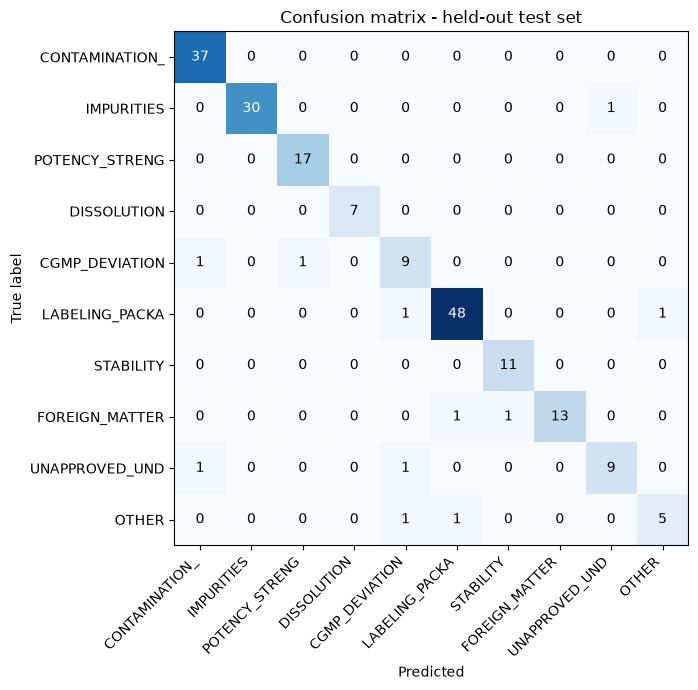

In [13]:
cats = [c for c in CATEGORIES if c in set(test.final_label) | set(test.model_pred)]
cm = confusion_matrix(test.final_label, test.model_pred, labels=cats)
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(cats))); ax.set_xticklabels([c[:14] for c in cats], rotation=45, ha="right")
ax.set_yticks(range(len(cats))); ax.set_yticklabels([c[:14] for c in cats])
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True label"); ax.set_title("Confusion matrix - held-out test set")
plt.tight_layout(); plt.savefig(OUT / "figures/confusion_matrix.png", dpi=110); plt.show()

**Reading the confusion matrix:** the diagonal shows correct predictions, and anything off the diagonal is a mistake. The table below lists the actual mistakes, because looking at errors tells us whether they are model failures or genuinely ambiguous texts that a human would also hesitate over.

In [14]:
errors = test[test.final_label != test.model_pred][["reason_clean", "final_label", "model_pred", "baseline_pred"]]
print(f"{len(errors)} errors out of {len(test)} test records")
errors.assign(reason_clean=errors.reason_clean.str[:100])

11 errors out of 197 test records


,reason_clean,final_label,model_pred,baseline_pred
276,Does Not Meet Monograph: NEW GPC INC. has recalled multiple Over-the-Counter Drug Products due to la,UNAPPROVED_UNDECLARED,CONTAMINATION_STERILITY,UNAPPROVED_UNDECLARED
288,"Discoloration: Brown spots were noted embedded in Amlodipine Besylate Tablets, 10 mg, Lot # MP4344.",FOREIGN_MATTER,STABILITY,STABILITY
388,Incorrect/Undeclared Excipient; product description section of testosterone cypionate incorrectly st,LABELING_PACKAGING,OTHER,UNAPPROVED_UNDECLARED
391,CGMP Deviations; deficiencies at the manufacturer may result in assay or content uniformity failures,CGMP_DEVIATION,POTENCY_STRENGTH,POTENCY_STRENGTH
526,CGMP Deviations: Product complaints received indicating reconstituted suspension was observed to be,OTHER,CGMP_DEVIATION,CGMP_DEVIATION
529,Defective Container: Potential for broken glass in the neck area of the glass bottles.,FOREIGN_MATTER,LABELING_PACKAGING,POTENCY_STRENGTH
557,Incorrect Product Formulation; Firm's customer resource center (CRC) statement indicates that the pr,OTHER,LABELING_PACKAGING,OTHER
707,Marketed Without an Approved NDA/ANDA: Product labeled to contain methanol making it an unapproved n,IMPURITIES,UNAPPROVED_UNDECLARED,UNAPPROVED_UNDECLARED
775,"CGMP Deviations: Voluntary recall of all hand sanitizer distributed after March 31, 2022, due to FDA",UNAPPROVED_UNDECLARED,CGMP_DEVIATION,CGMP_DEVIATION
887,cGMP Deviations: Observations were made that some blister card-foils were separating from the bliste,LABELING_PACKAGING,CGMP_DEVIATION,CGMP_DEVIATION


### 4.6 Confidence threshold: when the model should say "I'm not sure"
Every prediction comes with a probability. If the top probability is low, we **do not force** the record into a category; it is marked `UNCERTAIN_REVIEW` for a human.

**Choosing the threshold without touching the test set:**
* We take *out-of-fold* predictions on the **training** data, meaning each record is predicted by a model that did not see it.
* We pick the lowest threshold at which the predictions we keep are at least 95% correct.

**Then:**
* The final model is trained on all labels and applied to every record.
* Records that were labelled keep their label (`label_source = annotated`).

In [15]:
oof = cross_val_predict(new_model(), train.text, train.final_label, groups=train.text,
                        cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1), method="predict_proba")
classes = np.array(sorted(train.final_label.unique()))
oof_conf, oof_pred = oof.max(1), classes[oof.argmax(1)]
grid = pd.DataFrame([{"threshold": t, "coverage": (oof_conf >= t).mean(),
                      "accuracy_kept": (oof_pred[oof_conf >= t] == train.final_label.values[oof_conf >= t]).mean()}
                     for t in np.arange(0.30, 0.91, 0.05)]).round(3)
ok = grid[grid.accuracy_kept >= KEPT_ACCURACY_GOAL]
CONF_THRESHOLD = float(ok.threshold.min()) if len(ok) else 0.6
print(grid.to_string(index=False)); print("Chosen threshold:", CONF_THRESHOLD)

final_model = new_model().fit(labels.text, labels.final_label)
proba = final_model.predict_proba(df.reason_clean.map(preprocess))
df["predicted_category"] = final_model.classes_[proba.argmax(1)]
df["category_confidence"] = proba.max(1).round(3)
df["label_source"] = "model"
key = labels.set_index(["event_id", "reason_clean"]).final_label
annotated = pd.MultiIndex.from_arrays([df.event_id, df.reason_clean]).isin(key.index)
df.loc[annotated, "predicted_category"] = key.reindex(pd.MultiIndex.from_arrays([df.event_id[annotated], df.reason_clean[annotated]])).values
df.loc[annotated, ["label_source", "category_confidence"]] = ["annotated", 1.0]
df["analysis_category"] = np.where(df.category_confidence >= CONF_THRESHOLD, df.predicted_category, "UNCERTAIN_REVIEW")
SHARE_REVIEW = (df.analysis_category == "UNCERTAIN_REVIEW").mean()
joblib.dump({"model": final_model, "threshold": CONF_THRESHOLD, "snapshot_sha256": provenance["sha256"]}, OUT / "models/reason_classifier.joblib")
print(f"Records labelled by annotation: {annotated.sum():,} | by model: {(~annotated).sum():,} | sent to review: {SHARE_REVIEW:.1%}")
print(df.analysis_category.value_counts().to_string())

 threshold  coverage  accuracy_kept
      0.30     0.955          0.962
      0.35     0.930          0.972
      0.40     0.900          0.976
      0.45     0.873          0.981
      0.50     0.843          0.987
      0.55     0.808          0.992
      0.60     0.780          0.994
      0.65     0.750          0.993
      0.70     0.704          0.995
      0.75     0.646          0.998
      0.80     0.595          0.998
      0.85     0.511          0.998
      0.90     0.431          0.997
Chosen threshold: 0.3
Records labelled by annotation: 3,754 | by model: 14,256 | sent to review: 3.2%
analysis_category
CONTAMINATION_STERILITY    7283
IMPURITIES                 2378
CGMP_DEVIATION             2017
LABELING_PACKAGING         1847
POTENCY_STRENGTH            962
STABILITY                   924
FOREIGN_MATTER              770
UNAPPROVED_UNDECLARED       592
UNCERTAIN_REVIEW            583
DISSOLUTION                 399
OTHER                       255


**Test that the predictions make pharmaceutical sense.** The first valsartan recalls (2018) said only *"Carcinogen impurity detected in API"* and never named NDMA. A keyword search for "NDMA" would miss them. The classifier should still call them IMPURITIES.

In [16]:
carcinogen = df.reason_clean.str.contains("carcinogen impurity|ndma|ndea|nitros", case=False)
share_ok = (df.loc[carcinogen, "predicted_category"] == "IMPURITIES").mean()
print(f"Nitrosamine/carcinogen-impurity recalls classified as IMPURITIES: {share_ok:.1%} of {carcinogen.sum()}")
assert share_ok > 0.9
_ = df[["recall_number", "event_id", "analysis_category", "category_confidence", "label_source"]].to_sql("recall_categories", con, if_exists="replace", index=False)

Nitrosamine/carcinogen-impurity recalls classified as IMPURITIES: 100.0% of 558


## Section 5. Detecting unusual surges in recalls

### 5.1 Monthly counts
For three kinds of **series**, we count distinct recall **events** per month:
* each **failure category** (for example IMPURITIES),
* each **product group** (for example Ophthalmic),
* each **recalling firm**.

**Design choices that prevent cheating (look-ahead bias):**
* **Month = FDA publication month.** Outsiders only learn of a recall when FDA publishes it.
* **"Normal" is calculated from the previous 12 months only.** `shift(1)` excludes the current month, so a month never contributes to its own baseline.
* **Zero vs missing.** Inside the snapshot, a month without recalls is a true zero. Months after the snapshot are unknown, so we stop at the **last complete month**. The partial first month (June 2012) is dropped.

In [17]:
FIRST_MONTH = pd.Period("2012-07", "M")
LAST_MONTH = df.report_month.max() - 1               # the last month in the file is incomplete
ALL_MONTHS = pd.period_range(FIRST_MONTH, LAST_MONTH, freq="M")

def build_panel(data, month_col="report_month"):
    data = data[(data[month_col] >= FIRST_MONTH) & (data[month_col] <= LAST_MONTH)]
    parts = []
    for series_type, col in [("category", "analysis_category"), ("product_group", "product_group"), ("firm", "firm_std")]:
        g = data.groupby([col, month_col]).agg(n_events=("event_id", "nunique"), n_records=("recall_number", "size"),
                                                n_firms=("firm_std", "nunique"), n_class1=("is_class_I", "sum"))
        idx = pd.MultiIndex.from_product([data[col].unique(), ALL_MONTHS], names=["series_name", "month"])
        g = g.rename_axis(["series_name", "month"]).reindex(idx, fill_value=0).reset_index()
        g.insert(0, "series_type", series_type)
        parts.append(g)
    return pd.concat(parts, ignore_index=True)

def add_baselines(p):
    p = p.sort_values(["series_type", "series_name", "month"]).copy()
    keys = [p.series_type, p.series_name]
    past = p.groupby(["series_type", "series_name"]).n_events.shift(1)        # PAST months only
    roll = lambda f: past.groupby(keys).transform(lambda s: getattr(s.rolling(BASELINE_MONTHS, min_periods=BASELINE_MONTHS), f)())
    p["hist_mean"], p["hist_std"] = roll("mean"), roll("std")
    p["hist_q1"] = past.groupby(keys).transform(lambda s: s.rolling(BASELINE_MONTHS, min_periods=BASELINE_MONTHS).quantile(.25))
    p["hist_q3"] = past.groupby(keys).transform(lambda s: s.rolling(BASELINE_MONTHS, min_periods=BASELINE_MONTHS).quantile(.75))
    p["prev"] = past
    p["zscore"] = (p.n_events - p.hist_mean) / np.maximum(p.hist_std, STD_FLOOR)
    p["ratio_12m"] = (p.n_events + 1) / (p.hist_mean + 1)
    p["growth"] = (p.n_events - p.prev) / (p.prev + 1)
    p["class1_share"] = np.where(p.n_records > 0, p.n_class1 / p.n_records.replace(0, 1), 0)
    return p[p.hist_mean.notna()].copy()                                      # need 12 months of history

panel = add_baselines(build_panel(df))
print(panel.groupby("series_type").series_name.nunique().to_string())
print("Months scored:", panel.month.min(), "to", panel.month.max())

series_type
category           11
firm             1461
product_group       8
Months scored: 2013-07 to 2026-09


In [18]:
# Look-ahead test: recompute one baseline by hand from the 12 EARLIER months
row = panel[panel.series_type == "category"].sample(1, random_state=3).iloc[0]
hist = build_panel(df).query("series_type == @row.series_type and series_name == @row.series_name and month < @row.month").tail(12)
assert np.isclose(hist.n_events.mean(), row.hist_mean) and hist.month.max() < row.month
print(f"Look-ahead test passed: baseline for {row.series_name} {row.month} uses {hist.month.min()}..{hist.month.max()} only")

Look-ahead test passed: baseline for CONTAMINATION_STERILITY 2014-04 uses 2013-04..2014-03 only


### 5.2 Three detectors
| Method | How it decides a month is unusual | Strength | Weakness |
|---|---|---|---|
| **Rolling z-score** | (this month − 12-month mean) / 12-month spread ≥ 3 | Simple, easy to explain | A recent spike inflates the mean and spread and can hide a second wave |
| **IQR (Tukey fence)** | This month > Q3 + 1.5 × IQR of the past 12 months | Quartiles are barely moved by one past spike | Can be noisier |
| **Isolation Forest** | Machine learning: unusual months are "isolated" by fewer random splits | Combines many signals (growth, Class I share, number of firms…) | Harder to explain; needs training data |

**All three methods also require:**
* at least **3 events** in the month (one or two recalls is normal noise),
* a count **above** the 12-month average (we only look for surges, not drops).

**Isolation Forest is trained walk-forward.** To score year Y, the model learns only from months **before** 1 January of Y, then is retrained the next year. A month can never be judged by a model that has seen the future.

**Consensus alert** = flagged by **at least 2 of the 3** methods. These alerts are the highest priority.

In [19]:
def statistical_flags(p, z=Z_THRESHOLD, min_events=MIN_EVENTS):
    surge = (p.n_events >= min_events) & (p.n_events > p.hist_mean)
    p["flag_zscore"] = (surge & (p.zscore >= z)).astype(int)
    p["flag_iqr"] = (surge & (p.n_events > p.hist_q3 + IQR_K * (p.hist_q3 - p.hist_q1))).astype(int)
    return p

IF_FEATURES = ["f_events", "f_ratio12", "f_z", "f_growth", "class1_share", "f_records", "f_firms"]
def if_matrix(p):
    return pd.DataFrame({"f_events": np.log1p(p.n_events), "f_ratio12": np.log(p.ratio_12m), "f_z": p.zscore.clip(-5, 15),
                         "f_growth": p.growth.clip(-5, 15), "class1_share": p.class1_share,
                         "f_records": np.log1p(p.n_records), "f_firms": np.log1p(p.n_firms)}, index=p.index)

def walk_forward_iforest(p, first_year=2014):
    p = p.copy(); p["if_score"] = np.nan; p["flag_iforest"] = 0
    active = p.n_events >= 1                                   # score months with activity (sparse series)
    for st in p.series_type.unique():
        for year in range(first_year, LAST_MONTH.year + 1):
            train_rows = active & (p.series_type == st) & (p.month.dt.year < year)
            score_rows = active & (p.series_type == st) & (p.month.dt.year == year)
            if train_rows.sum() < 50 or score_rows.sum() == 0:
                continue
            forest = IsolationForest(n_estimators=200, random_state=RANDOM_STATE).fit(if_matrix(p[train_rows]))
            threshold = np.quantile(-forest.score_samples(if_matrix(p[train_rows])), 1 - IF_TOP_SHARE)
            scores = -forest.score_samples(if_matrix(p[score_rows]))
            p.loc[score_rows, "if_score"] = scores
            p.loc[score_rows, "flag_iforest"] = ((scores > threshold) & (p.loc[score_rows, "n_events"] >= MIN_EVENTS)
                                                 & (p.loc[score_rows, "n_events"] > p.loc[score_rows, "hist_mean"])).astype(int).values
    return p

METHODS = ["flag_zscore", "flag_iqr", "flag_iforest"]
scored = walk_forward_iforest(statistical_flags(panel))
scored = scored[scored.month >= pd.Period("2014-01", "M")].copy()     # common evaluation period for all methods
scored["n_methods"] = scored[METHODS].sum(1)
scored["flag_consensus"] = (scored.n_methods >= 2).astype(int)
ALL_METHODS = METHODS + ["flag_consensus"]
print("Evaluation period:", scored.month.min(), "to", scored.month.max())
print(scored.groupby("series_type")[ALL_METHODS].sum())

Evaluation period: 2014-01 to 2026-09
               flag_zscore  flag_iqr  flag_iforest  flag_consensus
series_type                                                       
category                29        85             9              27
firm                    24        59            28              32
product_group           19        38             6              17


## Section 6. Backtest: would the detectors have caught real crises?

### 6.1 Six known events (our "ground truth")
| Event | Approx. public date* | Series where it should appear | How its recalls are identified |
|---|---|---|---|
| Nitrosamines in sartans (valsartan…) | Jul 2018 | IMPURITIES | reason mentions NDMA/NDEA/NMBA/nitrosamine/"carcinogen", product is a *sartan* |
| NDMA in ranitidine / nizatidine | Sep 2019 | IMPURITIES | NDMA/nitrosamine + ranitidine or nizatidine |
| NDMA in metformin ER | May 2020 | IMPURITIES | NDMA/nitrosamine + metformin |
| Methanol in hand sanitisers | Jun 2020 | IMPURITIES, Topical | methanol + sanitiser |
| Benzene in aerosols / sunscreens | May 2021 | IMPURITIES, Topical, Inhalation | benzene |
| Contaminated eye drops | Feb 2023 | Ophthalmic, CONTAMINATION_STERILITY | contamination or sterility wording + ophthalmic or eye |

\*Public dates are approximate (FDA/CDC announcements) and should be cited in the report.

### 6.2 Strict scoring rules (so we cannot fool ourselves)
* **Peak month:** the month with the most of that event's recalls. It is used only for scoring, never by the detectors.
* An alert counts as **detecting** an event only if:
  * it is on one of the event's series,
  * it falls **between the event's first published recall and its peak**, and
  * that month actually **contains recalls from the event**.

  An alert caused by something else in the same series does not count.
* **Lead to peak** = peak month − first alert month. A positive value means the alert came before the peak.
* **Lead vs public** = public announcement month − first alert month. A positive value means the alert came *before* the news.

In [20]:
KNOWN_EVENTS = [
    dict(event="Nitrosamines in sartans", public="2018-07", start="2018-07", end="2019-12",
         series=[("category", "IMPURITIES")], reason=r"ndma|ndea|nmba|nitros|carcinogen", product=r"sartan"),
    dict(event="NDMA in ranitidine/nizatidine", public="2019-09", start="2019-09", end="2020-06",
         series=[("category", "IMPURITIES")], reason=r"ndma|nitros", product=r"ranitidine|nizatidine"),
    dict(event="NDMA in metformin ER", public="2020-05", start="2020-05", end="2020-12",
         series=[("category", "IMPURITIES")], reason=r"ndma|nitros", product=r"metformin"),
    dict(event="Methanol in hand sanitisers", public="2020-06", start="2020-06", end="2021-03",
         series=[("category", "IMPURITIES"), ("product_group", "Topical")], reason=r"methanol", product=r"saniti"),
    dict(event="Benzene in aerosols/sunscreens", public="2021-05", start="2021-05", end="2022-06",
         series=[("category", "IMPURITIES"), ("product_group", "Topical"), ("product_group", "Inhalation")], reason=r"benzene", product=r"."),
    dict(event="Contaminated eye drops", public="2023-02", start="2023-01", end="2023-12",
         series=[("product_group", "Ophthalmic"), ("category", "CONTAMINATION_STERILITY")],
         reason=r"steril|contamin|microb|bacteri|fung", product=r"ophthalm|eye"),
]

def event_profile(ev, month_col="report_month"):
    is_event = (df.reason_clean.str.contains(ev["reason"], case=False)
                & df.product_description.str.contains(ev["product"], case=False, na=False))
    months = pd.period_range(ev["start"], ev["end"], freq="M")
    return df[is_event].groupby(month_col).event_id.nunique().reindex(months, fill_value=0)

def series_mask(data, ev):
    m = pd.Series(False, index=data.index)
    for st, sn in ev["series"]:
        m |= (data.series_type == st) & (data.series_name == sn)
    return m

def backtest(data, events=KNOWN_EVENTS, month_col="report_month", methods=ALL_METHODS):
    rows = []
    for ev in events:
        profile = event_profile(ev, month_col)
        peak, first = profile.idxmax(), profile[profile > 0].index.min()
        event_months = set(profile[profile > 0].index)
        candidates = data[series_mask(data, ev) & (data.month >= first) & (data.month <= peak) & data.month.isin(event_months)]
        public = pd.Period(ev["public"], "M")
        for meth in methods:
            hits = candidates.loc[candidates[meth] == 1, "month"]
            fa = hits.min() if len(hits) else None
            rows.append({"event": ev["event"], "method": meth.replace("flag_", ""), "public": str(public),
                         "first_event_month": str(first), "peak": str(peak), "peak_events": int(profile.max()),
                         "detected": fa is not None, "first_alert": str(fa) if fa else "-",
                         "lead_to_peak_m": (peak - fa).n if fa else np.nan,
                         "lead_vs_public_m": (public - fa).n if fa else np.nan})
    return pd.DataFrame(rows)

bt = backtest(scored)
bt.pivot(index="event", columns="method", values="first_alert")

method,consensus,iforest,iqr,zscore
event,,,,
Benzene in aerosols/sunscreens,-,-,-,-
Contaminated eye drops,-,-,-,-
Methanol in hand sanitisers,2020-09,2020-09,2020-08,2020-09
NDMA in metformin ER,-,-,2020-07,-
NDMA in ranitidine/nizatidine,-,-,2020-01,-
Nitrosamines in sartans,2018-08,2018-08,2018-08,2018-08


In [21]:
print("Lead time to peak (months; 0 = alert in the peak month):")
print(bt.pivot(index="event", columns="method", values="lead_to_peak_m").to_string())
print("\nLead versus public announcement (months; negative = alert came AFTER the news):")
print(bt.pivot(index="event", columns="method", values="lead_vs_public_m").to_string())

Lead time to peak (months; 0 = alert in the peak month):
method                          consensus  iforest  iqr  zscore
event                                                          
Benzene in aerosols/sunscreens        NaN      NaN  NaN     NaN
Contaminated eye drops                NaN      NaN  NaN     NaN
Methanol in hand sanitisers           0.0      0.0  1.0     0.0
NDMA in metformin ER                  NaN      NaN  0.0     NaN
NDMA in ranitidine/nizatidine         NaN      NaN  0.0     NaN
Nitrosamines in sartans               0.0      0.0  0.0     0.0

Lead versus public announcement (months; negative = alert came AFTER the news):
method                          consensus  iforest  iqr  zscore
event                                                          
Benzene in aerosols/sunscreens        NaN      NaN  NaN     NaN
Contaminated eye drops                NaN      NaN  NaN     NaN
Methanol in hand sanitisers          -3.0     -3.0 -2.0    -3.0
NDMA in metformin ER          

### 6.3 Workload and method comparison
A detector that alerts constantly is useless to a busy team. The proposal's target is **fewer than about 2 alerts per month**. We split the alerts by audience:
* **Regulator watch-list:** failure-category and product-group series.
* **Supplier monitoring:** firm series.

**Unexplained alerts** are those not linked to the six known events. Some will be real problems that never made headlines, so this figure is an **upper bound** on false alarms, not a measured false-alarm rate.

In [22]:
explained = pd.Series(False, index=scored.index)
for ev in KNOWN_EVENTS:
    prof = event_profile(ev)
    explained |= series_mask(scored, ev) & scored.month.isin(set(prof[prof > 0].index))
scored["explained"] = explained
scored["audience"] = np.where(scored.series_type == "firm", "supplier", "watch_list")
N_MONTHS = scored.month.nunique()

summary = bt.groupby("method").agg(events_detected=("detected", "sum"), median_lead_to_peak=("lead_to_peak_m", "median"),
                                   median_lead_vs_public=("lead_vs_public_m", "median"))
for meth in ALL_METHODS:
    name = meth.replace("flag_", "")
    wl = scored[scored.audience == "watch_list"]
    summary.loc[name, "watch_alerts_per_month"] = wl[meth].sum() / N_MONTHS
    summary.loc[name, "unexplained_per_month"] = wl.loc[~wl.explained, meth].sum() / N_MONTHS
    summary.loc[name, "supplier_alerts_per_month"] = scored.loc[scored.audience == "supplier", meth].sum() / N_MONTHS
summary["detection_rate"] = summary.events_detected / len(KNOWN_EVENTS)
summary = summary.round(2).sort_values(["events_detected", "watch_alerts_per_month"], ascending=[False, True])
BEST_METHOD = summary.index[0]
print(summary.to_string())
print("\nBest method by detection (ties broken by lower workload):", BEST_METHOD)

           events_detected  median_lead_to_peak  median_lead_vs_public  watch_alerts_per_month  unexplained_per_month  supplier_alerts_per_month  detection_rate
method                                                                                                                                                          
iqr                      4                  0.0                   -2.0                    0.80                   0.76                       0.39            0.67
iforest                  2                  0.0                   -2.0                    0.10                   0.08                       0.18            0.33
consensus                2                  0.0                   -2.0                    0.29                   0.27                       0.21            0.33
zscore                   2                  0.0                   -2.0                    0.31                   0.30                       0.16            0.33

Best method by detection (ties br

### 6.4 Threshold sensitivity: are the results fragile?
The thresholds (z ≥ 3, at least 3 events) were fixed **before** the backtest. To show the trade-off honestly, rather than tuning to six famous events, we re-run the statistical detectors over a small grid. Lower thresholds catch more events but produce more alerts.

In [23]:
sens = []
for min_ev in [2, 3, 4]:
    for z in [2.5, 3.0, 3.5]:
        tmp = statistical_flags(scored.copy(), z=z, min_events=min_ev)
        b = backtest(tmp, methods=["flag_zscore", "flag_iqr"])
        wl = tmp[tmp.audience == "watch_list"]
        sens.append({"min_events": min_ev, "z": z, "zscore_detected": int(b[b.method == "zscore"].detected.sum()),
                     "zscore_alerts_pm": round(wl.flag_zscore.sum() / N_MONTHS, 2),
                     "iqr_detected": int(b[b.method == "iqr"].detected.sum()), "iqr_alerts_pm": round(wl.flag_iqr.sum() / N_MONTHS, 2)})
pd.DataFrame(sens)

,min_events,z,zscore_detected,zscore_alerts_pm,iqr_detected,iqr_alerts_pm
0,2,2.5,3,0.52,5,0.9
1,2,3.0,2,0.31,5,0.9
2,2,3.5,2,0.19,5,0.9
3,3,2.5,3,0.52,4,0.8
4,3,3.0,2,0.31,4,0.8
5,3,3.5,2,0.19,4,0.8
6,4,2.5,3,0.49,4,0.7
7,4,3.0,2,0.31,4,0.7
8,4,3.5,2,0.19,4,0.7


### 6.5 "What if" analysis: what if recalls were visible the day they started?
FDA publishes about 7 weeks after a recall starts. As an **optimistic upper bound**, we rebuild the panels using the **initiation date**, as if a regulator learnt of each recall immediately (for example through direct firm notifications). This shows how much of the delay is caused by FDA's publication lag.

In [24]:
scored_init = statistical_flags(add_baselines(build_panel(df, "initiation_month")))
scored_init = scored_init[scored_init.month >= pd.Period("2014-01", "M")]
bt_init = backtest(scored_init, month_col="initiation_month", methods=["flag_zscore", "flag_iqr"])
pd.DataFrame({"detected (publication date)": bt[bt.method.isin(["zscore", "iqr"])].groupby("method").detected.sum(),
              "detected (initiation date)": bt_init.groupby("method").detected.sum(),
              "median lead vs public (publication)": bt[bt.method.isin(["zscore", "iqr"])].groupby("method").lead_vs_public_m.median(),
              "median lead vs public (initiation)": bt_init.groupby("method").lead_vs_public_m.median()})

,detected (publication date),detected (initiation date),median lead vs public (publication),median lead vs public (initiation)
method,,,,
iqr,4,2,-2.0,0.0
zscore,2,2,-2.0,0.0


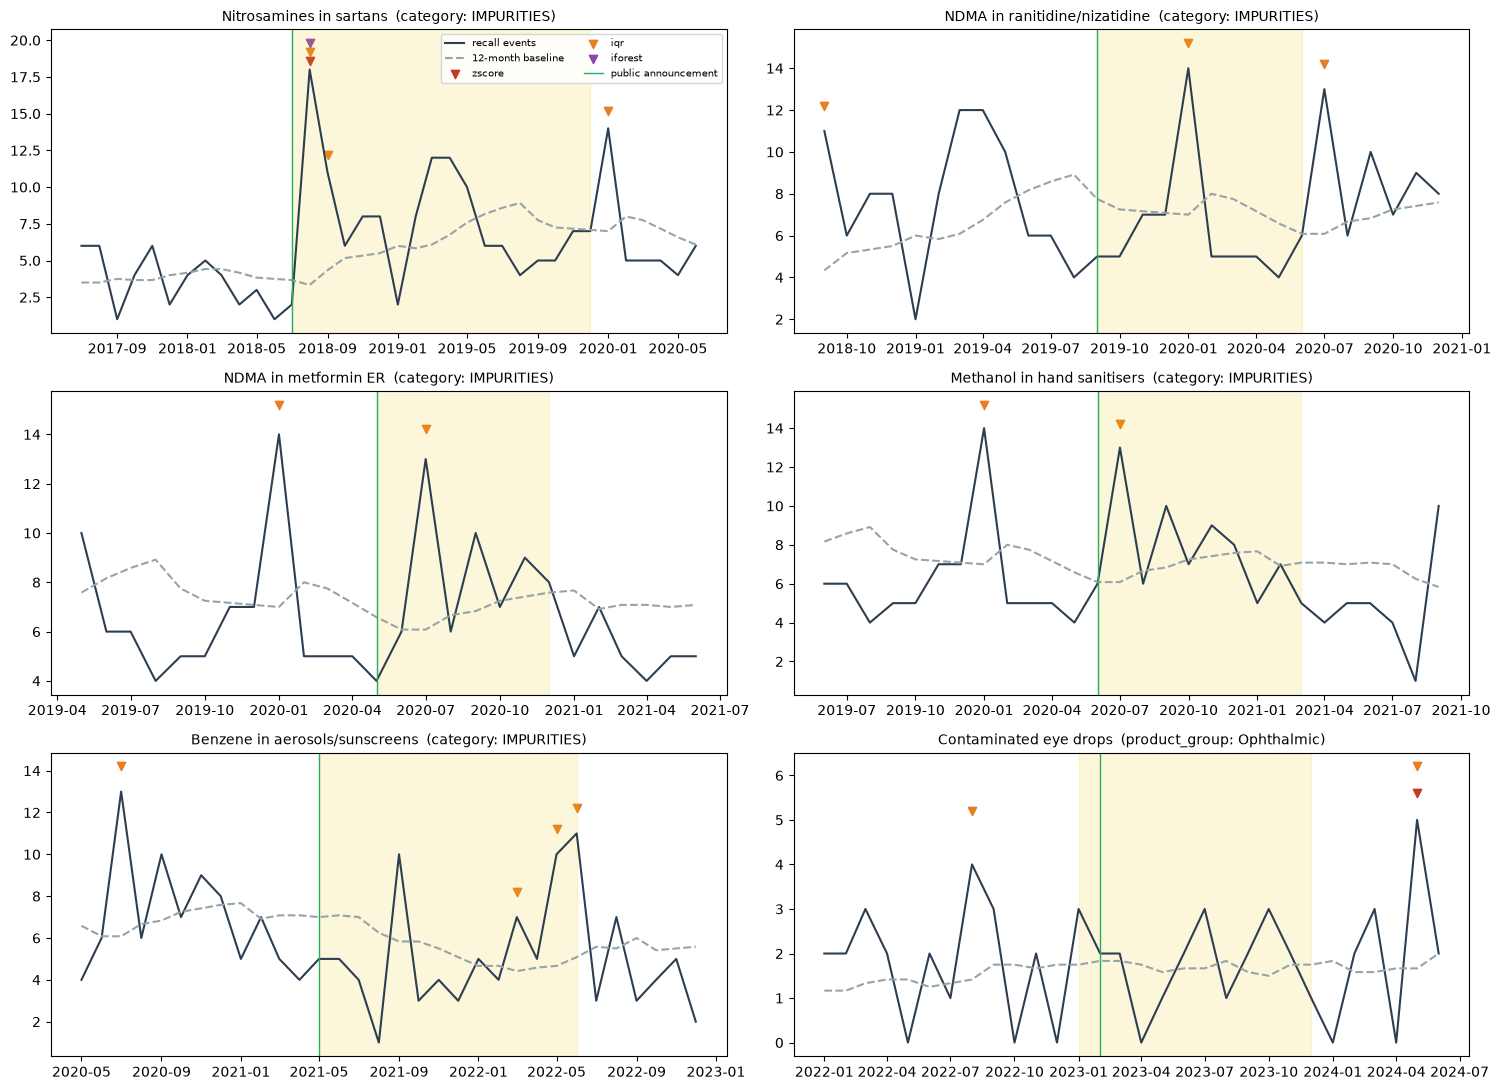

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(15, 11)); axes = axes.ravel()
colours = {"flag_zscore": "#c0392b", "flag_iqr": "#e67e22", "flag_iforest": "#8e44ad"}
for ax, ev in zip(axes, KNOWN_EVENTS):
    st, sn = ev["series"][0]
    s = scored[(scored.series_type == st) & (scored.series_name == sn)]
    s = s[(s.month >= pd.Period(ev["start"], "M") - 12) & (s.month <= pd.Period(ev["end"], "M") + 6)]
    x = s.month.dt.to_timestamp()
    ax.plot(x, s.n_events, color="#2c3e50", label="recall events"); ax.plot(x, s.hist_mean, "--", color="#95a5a6", label="12-month baseline")
    for k, (meth, col) in enumerate(colours.items()):
        h = s[s[meth] == 1]
        ax.scatter(h.month.dt.to_timestamp(), h.n_events + 0.6 * (k + 1), marker="v", color=col, label=meth[5:])
    ax.axvspan(pd.Period(ev["start"], "M").to_timestamp(), pd.Period(ev["end"], "M").to_timestamp(), color="#f1c40f", alpha=.15)
    ax.axvline(pd.Period(ev["public"], "M").to_timestamp(), color="#27ae60", lw=1, label="public announcement")
    ax.set_title(f"{ev['event']}  ({st}: {sn})", fontsize=10)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(OUT / "figures/backtests.png", dpi=110); plt.show()

**How to read the charts:**
* The black line is the monthly count of recall events. The dashed line is "normal", calculated from the past 12 months only.
* Triangles are alerts from each method. The yellow band is the event window and the green line is the public announcement.
* The interpretation printed in Section 9 is generated from these results.

## Section 7. Supplier evidence and tender screening (the commercial use)

### 7.1 Firm evidence table: transparent flags, not a secret score
For every recalling firm we compute plain counts (totals, last 12 months, Class I, alerts, main failure types) and up to four **evidence flags**:

| Flag | Rule |
|---|---|
| Recent anomaly alert | The firm's monthly series was flagged by any detector in the last 12 months |
| Recent Class I recall | At least one Class I (most serious) recall in the last 12 months |
| Rising trend | At least 3 events in the last 12 months **and** at least twice its average yearly count over the previous 3 years |
| Recurring failure | The same failure category at least 3 times in the last 4 years |

**Why flags instead of a weighted "risk score"?**
* A score such as "73/100" hides arbitrary weights and looks like an official rating.
* Flags are **explainable in one sentence each** and can be checked against the listed recall numbers.
* The table is an **investigation queue, not a verdict**.

In [26]:
RECENT_START = LAST_MONTH - 11
PRIOR_START, PRIOR_END = LAST_MONTH - 47, LAST_MONTH - 12
in_panel = df[(df.report_month >= FIRST_MONTH) & (df.report_month <= LAST_MONTH)]
recent, prior = in_panel[in_panel.report_month >= RECENT_START], in_panel[in_panel.report_month.between(PRIOR_START, PRIOR_END)]
last4y = in_panel[in_panel.report_month >= LAST_MONTH - 47]
events = df.drop_duplicates("event_id")

def top3(s):
    return "; ".join(f"{k} ({v})" for k, v in s.value_counts().head(3).items())

fe = df.groupby("firm_std").agg(
    recorded_names=("recalling_firm", lambda s: " | ".join(sorted(s.unique())[:3])),
    address_countries=("country", lambda s: ", ".join(sorted(s.dropna().unique()))),
    openfda_manufacturer=("openfda.manufacturer_name", lambda s: "; ".join(sorted(s.dropna().str.replace(r"[\[\]']", "", regex=True).unique())[:2])),
    total_events=("event_id", "nunique"))
fe["class_I_events"] = df[df.is_class_I].groupby("firm_std").event_id.nunique()
fe["events_12m"] = recent.groupby("firm_std").event_id.nunique()
fe["class_I_events_12m"] = recent[recent.is_class_I].groupby("firm_std").event_id.nunique()
fe["prior_events_per_year"] = prior.groupby("firm_std").event_id.nunique() / 3
firm_alerts = scored[(scored.series_type == "firm") & (scored.n_methods >= 1)]
fe["alert_months_12m"] = firm_alerts[firm_alerts.month >= RECENT_START].groupby("series_name").size()
fe["top_failures"] = events.groupby("firm_std").analysis_category.apply(top3)
fe["latest_recall_numbers"] = df.sort_values("report_date_dt", ascending=False).groupby("firm_std").recall_number.apply(lambda s: ", ".join(s.head(5)))
recurring = last4y.drop_duplicates("event_id").groupby(["firm_std", "analysis_category"]).size()
recurring = recurring[(recurring >= 3) & (recurring.index.get_level_values(1) != "UNCERTAIN_REVIEW")]
fe["recurring_failure"] = recurring.reset_index().groupby("firm_std").analysis_category.apply(lambda s: ", ".join(s))
fe = fe.fillna({"class_I_events": 0, "events_12m": 0, "class_I_events_12m": 0, "prior_events_per_year": 0, "alert_months_12m": 0,
                "recurring_failure": "", "openfda_manufacturer": ""})

def firm_flags(r):
    flags = []
    if r.alert_months_12m > 0: flags.append("Recent anomaly alert")
    if r.class_I_events_12m > 0: flags.append("Recent Class I recall")
    if r.events_12m >= 3 and r.events_12m >= 2 * max(r.prior_events_per_year, 0.5): flags.append("Rising trend")
    if r.recurring_failure: flags.append(f"Recurring failure: {r.recurring_failure}")
    return flags
fe["flags"] = fe.apply(lambda r: "; ".join(firm_flags(r)), axis=1)
fe["n_flags"] = fe.apply(lambda r: len(firm_flags(r)), axis=1)
fe = fe.reset_index()
fe.to_sql("firm_evidence", con, if_exists="replace", index=False)
watch = fe[fe.events_12m > 0].sort_values(["n_flags", "events_12m"], ascending=False)
print(f"Recent window: {RECENT_START} to {LAST_MONTH}. Firms with recalls in the window: {len(watch)}")
watch[["firm_std", "events_12m", "class_I_events_12m", "prior_events_per_year", "alert_months_12m", "flags"]].head(12)

Recent window: 2025-10 to 2026-09. Firms with recalls in the window: 202


,firm_std,events_12m,class_I_events_12m,prior_events_per_year,alert_months_12m,flags
293,carefusion 213,5.0,1.0,1.000000,1.0,Recent anomaly alert; Recent Class I recall; Rising trend; Recurring failure: CONTAMINATION_STERILITY
1245,sun pharmaceutical industries,12.0,1.0,10.666667,1.0,"Recent anomaly alert; Recent Class I recall; Recurring failure: CGMP_DEVIATION, DISSOLUTION, FOREIGN_MATTE..."
1284,teva pharmaceuticals usa,10.0,0.0,5.000000,1.0,"Recent anomaly alert; Rising trend; Recurring failure: DISSOLUTION, IMPURITIES, LABELING_PACKAGING, POTENC..."
194,baxter healthcare,5.0,3.0,3.333333,1.0,"Recent anomaly alert; Recent Class I recall; Recurring failure: CONTAMINATION_STERILITY, FOREIGN_MATTER, L..."
95,american regent,3.0,2.0,1.333333,0.0,Recent Class I recall; Rising trend; Recurring failure: FOREIGN_MATTER
562,haleon us holdings,3.0,1.0,0.666667,0.0,Recent Class I recall; Rising trend; Recurring failure: LABELING_PACKAGING
640,integradose compounding services,3.0,1.0,1.000000,0.0,Recent Class I recall; Rising trend; Recurring failure: POTENCY_STRENGTH
320,cipla usa,8.0,0.0,1.666667,0.0,"Rising trend; Recurring failure: IMPURITIES, OTHER"
480,fresenius kabi usa,6.0,3.0,0.333333,0.0,Recent Class I recall; Rising trend
532,golden state medical supply,6.0,0.0,2.666667,0.0,"Rising trend; Recurring failure: DISSOLUTION, IMPURITIES"


### 7.2 Tender screening: one evidence brief per bidder
**The procurement use case:** a buyer is evaluating bids for a product (for example *metformin tablets*). For each bidder, `tender_screen()` produces:
1. **Match status.** We look for the bidder's name among US recalling firms.
   * Similar-named entities (for example "Teva Pharmaceuticals" and "Teva Pharmaceuticals USA") are **listed, never merged**.
   * If a bidder is **not found**, the brief says so clearly. *No FDA record is not evidence of good quality.*
2. **Recall evidence:** totals, last 12 months, Class I recalls, flags, and **product-specific recalls** with recall numbers.
3. **Checks to request before award,** tailored to the evidence. For example, a firm with impurity recalls, or a nitrosamine-prone product, triggers a request for a nitrosamine risk assessment.

Each brief is saved as a Markdown file in `outputs/tender_briefs/`, ready to attach to a tender evaluation report.

In [27]:
GENERIC_WORDS = {"pharmaceutical", "pharmaceuticals", "pharma", "pharmacy", "health", "healthcare", "medical", "laboratories",
                 "labs", "the", "international", "american", "global", "national", "generic", "generics", "united", "general",
                 "which", "what", "have", "has", "kenya", "kenyan", "fda", "nairobi", "mombasa", "best", "first", "quality",
                 "drug", "drugs", "should", "show", "tell", "are", "how", "is", "did", "does", "can", "list"}
NITROSAMINE_PRONE = r"sartan|ranitidine|nizatidine|metformin|rifampin|rifapentine|varenicline|sitagliptin|propranolol|duloxetine"

def match_bidder(name):
    std = standardise_firm(name)
    fe_idx = fe.set_index("firm_std")
    if std in fe_idx.index:
        return std, "exact name match"
    first = std.split()[0] if std else ""
    if first and first not in GENERIC_WORDS:
        cands = [f for f in fe_idx.index if f.split()[0] == first]
        if cands:
            return fe_idx.loc[cands, "total_events"].idxmax(), "matched on brand word - confirm it is the same company"
    return None, "not found"

def related_entities(firm):
    first = firm.split()[0]
    if first in GENERIC_WORDS:
        return []
    return [f for f in fe.firm_std if f.split()[0] == first and f != firm]

def checks_for(firm_row, product, product_recalls):
    checks = ["Confirm the actual manufacturing site of the tendered product (the recalling firm may be a repackager or distributor).",
              "Verify Pharmacy and Poisons Board (PPB) registration of the product and of that manufacturing site.",
              "Request the current GMP certificate / latest inspection outcome for the site (PPB, WHO PQ or a stringent regulator).",
              "Request certificates of analysis for the batches to be supplied."]
    failures = (firm_row.top_failures if firm_row is not None else "") + " " + " ".join(product_recalls.analysis_category if len(product_recalls) else [])
    if re.search(NITROSAMINE_PRONE, product, re.I) or "IMPURITIES" in failures:
        checks.append("Request a nitrosamine risk assessment and NDMA/NDEA test results for the API and finished product.")
    if "CONTAMINATION_STERILITY" in failures:
        checks.append("Request sterility-assurance evidence (media fills, environmental monitoring) for sterile products.")
    if "DISSOLUTION" in failures or "STABILITY" in failures:
        checks.append("Request dissolution profiles and real-time stability data covering the full shelf life (Zone IVb conditions for Kenya).")
    if "LABELING_PACKAGING" in failures:
        checks.append("Inspect labelling/packaging samples and ask how line clearance prevents mix-ups.")
    if firm_row is not None and firm_row.class_I_events_12m > 0:
        checks.append("Ask for the root-cause investigation and CAPA for the recent Class I recall(s).")
    return checks

def tender_screen(bidders, product):
    rows = []
    for bidder in bidders:
        firm, how = match_bidder(bidder)
        r = fe.set_index("firm_std").loc[firm] if firm else None
        prod = df[(df.firm_std == firm) & df.product_description.str.contains(product, case=False, na=False)] if firm else df.iloc[0:0]
        prod_events = prod.drop_duplicates("event_id").sort_values("report_date_dt", ascending=False)
        lines = [f"# Tender evidence brief - {bidder} - {product}",
                 f"*Source: {provenance['source']}, snapshot {provenance['effective_snapshot_date']}. Decision support only - not a supplier rating.*", ""]
        if firm is None:
            lines += ["**No US FDA recall record found under this name.** This is NOT evidence of good quality: the firm may not supply "
                      "the US market or may trade under another name.", ""]
        else:
            rel = related_entities(firm)
            lines += [f"**Matched recalling firm:** `{firm}` ({how}). Recorded as: {r.recorded_names}.",
                      f"Address country of recalling firm: {r.address_countries} (not necessarily the manufacturing site). "
                      f"Manufacturer named by openFDA: {r.openfda_manufacturer or 'not provided'}.",
                      f"Similar-named entities (NOT merged): {', '.join(rel[:5]) if rel else 'none'}.", "",
                      "## Recall evidence",
                      f"- Total recall events: {int(r.total_events)} (Class I: {int(r.class_I_events)})",
                      f"- Last 12 months ({RECENT_START} to {LAST_MONTH}): {int(r.events_12m)} events, {int(r.class_I_events_12m)} Class I",
                      f"- Main failure types: {r.top_failures}",
                      f"- Evidence flags: {r['flags'] or 'none'}",
                      f"- {product.title()} recalls by this firm: {len(prod_events)}"]
            lines += [f"  - {p.recall_number} | {p.report_date_dt.date()} | {p.classification} | {p.analysis_category} | {p.reason_clean[:110]}"
                      for p in prod_events.head(6).itertuples()]
        lines += ["", "## Checks to request before award"] + [f"- [ ] {c}" for c in checks_for(r, product, prod_events)]
        path = OUT / "tender_briefs" / f"{re.sub(r'[^a-z0-9]+', '_', bidder.lower())}_{product.lower()}.md"
        path.write_text("\n".join(lines))
        rows.append({"bidder": bidder, "matched_firm": firm or "-", "match": how,
                     "events_total": int(r.total_events) if firm else 0, "events_12m": int(r.events_12m) if firm else 0,
                     "class_I_12m": int(r.class_I_events_12m) if firm else 0, f"{product}_recalls": len(prod_events),
                     "flags": (r["flags"] or "none") if firm else "no FDA record", "brief": str(path)})
    return pd.DataFrame(rows)

tender_demo = tender_screen(["Sun Pharmaceutical Industries", "Lupin Pharmaceuticals", "Marksans Pharma", "Nairobi Generics Ltd"], "metformin")
tender_demo

,bidder,matched_firm,match,events_total,events_12m,class_I_12m,metformin_recalls,flags,brief
0,Sun Pharmaceutical Industries,sun pharmaceutical industries,exact name match,95,12,1,7,"Recent anomaly alert; Recent Class I recall; Recurring failure: CGMP_DEVIATION, DISSOLUTION, FOREIGN_MATTE...",outputs\tender_briefs\sun_pharmaceutical_industries_metformin.md
1,Lupin Pharmaceuticals,lupin pharmaceuticals,exact name match,91,6,0,2,"Recurring failure: FOREIGN_MATTER, IMPURITIES, LABELING_PACKAGING, POTENCY_STRENGTH",outputs\tender_briefs\lupin_pharmaceuticals_metformin.md
2,Marksans Pharma,marksans pharma,exact name match,3,0,0,2,none,outputs\tender_briefs\marksans_pharma_metformin.md
3,Nairobi Generics Ltd,-,not found,0,0,0,0,no FDA record,outputs\tender_briefs\nairobi_generics_ltd_metformin.md


In [28]:
print(Path(tender_demo.brief.iloc[0]).read_text())

# Tender evidence brief - Sun Pharmaceutical Industries - metformin
*Source: openFDA Drug Enforcement Reports (https://open.fda.gov/apis/drug/enforcement/), snapshot 2026-10-07. Decision support only - not a supplier rating.*

**Matched recalling firm:** `sun pharmaceutical industries` (exact name match). Recorded as: SUN PHARMACEUTICAL INDUSTRIES INC | Sun Pharmaceutical Industries Inc. | Sun Pharmaceutical Industries Ltd..
Address country of recalling firm: India, United States (not necessarily the manufacturing site). Manufacturer named by openFDA: Discount Drug Mart; Ferring Pharmaceuticals Inc..
Similar-named entities (NOT merged): sun pharma global, sun pharma global fze, sun pharma taro.

## Recall evidence
- Total recall events: 95 (Class I: 2)
- Last 12 months (2025-10 to 2026-09): 12 events, 1 Class I
- Main failure types: FOREIGN_MATTER (19); IMPURITIES (18); DISSOLUTION (15)
- Evidence flags: Recent anomaly alert; Recent Class I recall; Recurring failure: CGMP_DEVIATION, DI

### 7.3 This month's watch-list
These are the alerts a monitoring team would review today, from the last 6 complete months. Consensus alerts (two or more methods agreeing) come first, and each comes with a plain-language explanation.

In [29]:
def explain(r):
    methods = [n for n, f in [("z-score", r.flag_zscore), ("IQR", r.flag_iqr), ("Isolation Forest", r.flag_iforest)] if f]
    return (f"{int(r.n_events)} recall events in {r.month} vs a 12-month average of {r.hist_mean:.1f} "
            f"(z = {r.zscore:.1f}); flagged by {', '.join(methods)}; {r.class1_share:.0%} of records Class I.")
alerts = scored[scored.n_methods >= 1].copy()
alerts["why_flagged"] = alerts.apply(explain, axis=1)
alerts_out = alerts.assign(month=alerts.month.astype(str))[["series_type", "series_name", "month", "n_events", "hist_mean", "zscore",
                                                             "n_methods", "explained", "why_flagged"]]
alerts_out.to_sql("alerts", con, if_exists="replace", index=False)
current = alerts_out[alerts_out.month > str(LAST_MONTH - 6)].sort_values(["n_methods", "n_events"], ascending=False)
current.head(12)

,series_type,series_name,month,n_events,hist_mean,zscore,n_methods,explained,why_flagged
165,category,CONTAMINATION_STERILITY,2026-04,12,3.750000,4.113331,3,False,"12 recall events in 2026-04 vs a 12-month average of 3.8 (z = 4.1); flagged by z-score, IQR, Isolation For..."
2904,product_group,Oral liquid,2026-07,7,1.250000,4.237909,3,False,"7 recall events in 2026-07 vs a 12-month average of 1.2 (z = 4.2); flagged by z-score, IQR, Isolation Fore..."
9057,firm,teva pharmaceuticals usa,2026-04,4,0.416667,3.583333,3,False,"4 recall events in 2026-04 vs a 12-month average of 0.4 (z = 3.6); flagged by z-score, IQR, Isolation Fore..."
2902,product_group,Oral liquid,2026-05,5,1.166667,3.833333,2,False,"5 recall events in 2026-05 vs a 12-month average of 1.2 (z = 3.8); flagged by z-score, IQR; 0% of records ..."
14361,firm,carefusion 213,2026-07,3,0.166667,2.833333,2,False,"3 recall events in 2026-07 vs a 12-month average of 0.2 (z = 2.8); flagged by IQR, Isolation Forest; 13% o..."
1366,category,FOREIGN_MATTER,2026-08,7,2.583333,2.634478,1,False,7 recall events in 2026-08 vs a 12-month average of 2.6 (z = 2.6); flagged by IQR; 17% of records Class I.
1023,category,POTENCY_STRENGTH,2026-07,7,2.166667,2.848669,1,False,7 recall events in 2026-07 vs a 12-month average of 2.2 (z = 2.8); flagged by IQR; 0% of records Class I.
1196,category,DISSOLUTION,2026-09,6,1.916667,2.713103,1,False,6 recall events in 2026-09 vs a 12-month average of 1.9 (z = 2.7); flagged by IQR; 0% of records Class I.
1193,category,DISSOLUTION,2026-06,5,1.750000,2.395340,1,False,5 recall events in 2026-06 vs a 12-month average of 1.8 (z = 2.4); flagged by IQR; 0% of records Class I.
1020,category,POTENCY_STRENGTH,2026-04,4,1.916667,1.284935,1,False,4 recall events in 2026-04 vs a 12-month average of 1.9 (z = 1.3); flagged by IQR; 0% of records Class I.


## Section 8. The AI assistant: ask the findings in plain English

### 8.1 How it works (and why it is trustworthy)
```
question ──► ROUTER (code) ──► SQL facts (exact numbers)  ─┐
                          └──► SEARCH MODEL (embeddings) ─┤──► CLAUDE writes the answer ──► CHECKER (code) ──► answer + sources
                               finds the relevant records ┘    using ONLY this evidence     verifies every number & recall ID
```
| Specialist | Job | Why it is used |
|---|---|---|
| Router (code) | Detects firm names, products, failure types and intent | Transparent rules that can be tested |
| SQL | All counts, dates, rankings | Exact; a language model cannot count reliably |
| Embedding model + ChromaDB | Finds recall records with similar *meaning* | "eye drop infection" finds "ophthalmic … Pseudomonas" |
| Claude (LLM) | Explains the evidence in plain language | Good at language, but told to use **only** the evidence given |
| Checker (code) | Every number and recall ID in the answer must appear in the evidence; otherwise Claude is asked to correct itself once, and any remaining problems are shown to the user | Catches invented facts automatically |

**Safeguards in the instructions given to Claude (the system prompt):**
* Never invent firms, numbers or recall IDs.
* Separate facts from interpretation.
* Say when information is missing.
* Treat an anomaly as a signal, not proof.
* Never recommend accepting or rejecting a supplier; list checks instead.

### 8.2 The knowledge base
Each document carries its **source**:

| Document type | One per |
|---|---|
| Recall event | recall event (about 4,700) |
| Firm evidence | firm |
| Anomaly alert | alert, with its explanation |
| Yearly category summary | failure category |
| Project notes | written in this notebook and clearly labelled as such (methods, limitations, procurement checklist) |

In [30]:
docs, metas, ids = [], [], []
def add(doc_id, text, meta):
    ids.append(doc_id); docs.append(text); metas.append(meta)

SRC = f"openFDA snapshot {provenance['effective_snapshot_date']}"
for eid, g in df.groupby("event_id"):
    f = g.iloc[0]
    add(f"event-{eid}", f"Recall event {eid}: {f.recalling_firm} ({f.country}). {f.classification}, {f.status}. "
        f"Published {f.report_date_dt.date()}. Reason: {f.reason_clean[:350]}. Failure category: {f.analysis_category}. "
        f"Product group: {f.product_group}. Products: {'; '.join(g.product_description.astype(str).str[:90].head(2))}. "
        f"Recall numbers: {', '.join(g.recall_number.head(5))}{' ...' if len(g) > 5 else ''}.",
        {"doc_type": "recall_event", "firm_std": f.firm_std, "source": SRC})
for r in fe.itertuples():
    add(f"firm-{r.firm_std}", f"Firm evidence for {r.recorded_names}: {int(r.total_events)} recall events ({int(r.class_I_events)} Class I); "
        f"last 12 months {int(r.events_12m)} events ({int(r.class_I_events_12m)} Class I); main failures {r.top_failures}; "
        f"flags: {r.flags or 'none'}; latest recall numbers {r.latest_recall_numbers}.",
        {"doc_type": "firm_evidence", "firm_std": r.firm_std, "source": SRC + " (derived)"})
for i, r in alerts.iterrows():
    add(f"alert-{i}", f"Anomaly alert for {r.series_type} '{r.series_name}': {r.why_flagged} An alert is a signal for investigation, not a confirmed quality failure.",
        {"doc_type": "alert", "firm_std": r.series_name if r.series_type == "firm" else "", "source": "Anomaly detection (this notebook)"})
yearly = events.groupby([events.report_date_dt.dt.year, "analysis_category"]).size().unstack(fill_value=0)
for cat in yearly.columns:
    add(f"category-{cat}", f"Recall events per year classified as {cat}: " + ", ".join(f"{y}: {n}" for y, n in yearly[cat].items()) + ".",
        {"doc_type": "category_summary", "firm_std": "", "source": SRC + " (derived)"})
NOTES = {
 "limitations": "Limitations of US FDA recall data for Kenyan procurement: covers products sold in the US market only; a firm may supply Kenya "
   "from a different site or with different products; no FDA recall does not prove good quality; the recalling firm is often a repackager, "
   "distributor or compounding pharmacy rather than the manufacturer; FDA publishes recalls about 7 weeks after they start; Kenyan PPB "
   "data, WHO prequalification and GMP inspection reports must be checked separately.",
 "procurement-checks": "Checks before awarding a pharmaceutical supply contract (decision support, not a decision): confirm the actual "
   "manufacturing site; verify PPB registration of product and site; obtain the current GMP certificate or inspection outcome; request "
   "certificates of analysis; for nitrosamine-prone products request a nitrosamine risk assessment; for sterile products request sterility "
   "assurance evidence; request stability data for Zone IVb; consider independent testing at the national quality control laboratory.",
 "methods": "Methods: recall reasons classified by TF-IDF + logistic regression into 10 categories; monthly recall events by FDA publication "
   "month; alerts from rolling z-score, IQR and walk-forward Isolation Forest using only the previous 12 months; consensus = 2 or more methods.",
}
for k, t in NOTES.items():
    add(f"note-{k}", t, {"doc_type": "project_note", "firm_std": "", "source": "Project documentation (this notebook, not FDA data)"})
print(pd.Series([m["doc_type"] for m in metas]).value_counts().to_string())

recall_event        4705
firm_evidence       1468
alert                193
category_summary      11
project_note           3


### 8.3 Embeddings and the vector database
An **embedding** is a list of 384 numbers that captures the *meaning* of a text. Texts with similar meaning get similar numbers. We use the free `all-MiniLM-L6-v2` model, which runs on a laptop CPU.

**Fallback:** if the model cannot be downloaded (for example with no internet), the code switches automatically to a clearly labelled **LSA fallback**:
* LSA (*Latent Semantic Analysis*) is TF-IDF compressed into 256 "topics".
* It matches words that tend to appear together rather than deep meaning, so it is weaker.
* The method actually used is printed.

**ChromaDB** stores the vectors and their metadata on disk and finds the documents closest to a question.

In [31]:
try:
    from sentence_transformers import SentenceTransformer
    _st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    embed = lambda texts: _st.encode(list(texts), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    EMBEDDING_METHOD, MAX_DISTANCE = "all-MiniLM-L6-v2 (semantic embeddings)", 0.60
except Exception as e:
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import normalize
    print("Embedding model unavailable (", type(e).__name__, ") -> LSA fallback")
    _tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
    _svd = TruncatedSVD(256, random_state=RANDOM_STATE).fit(_tf.fit_transform(docs))
    embed = lambda texts: normalize(_svd.transform(_tf.transform(list(texts))))
    EMBEDDING_METHOD, MAX_DISTANCE = "LSA fallback (TF-IDF + SVD)", 0.80

# ---- Vector database: a small, pure-Python store (no ChromaDB needed) ----
# ChromaDB crashed the Jupyter kernel on this Windows/Anaconda setup, so we store the vectors in a NumPy array.
# It offers the same functions the assistant uses (add, query, get, count) and saves to disk in outputs/vector_db/.
# For ~6,000 documents an exact search over all vectors takes milliseconds, so no special index is needed.
class SimpleVectorStore:
    def __init__(self):
        self.ids, self.documents, self.metadatas, self.vectors = [], [], [], None

    def add(self, ids, documents, metadatas, embeddings):
        new = np.asarray(embeddings, dtype="float32")
        self.vectors = new if self.vectors is None else np.vstack([self.vectors, new])
        self.ids += list(ids); self.documents += list(documents); self.metadatas += list(metadatas)

    def count(self):
        return len(self.ids)

    def _matches(self, meta, where):
        # supports {"field": value} and {"field": {"$ne": value}}, the two filters the assistant uses
        for field, rule in (where or {}).items():
            if isinstance(rule, dict) and "$ne" in rule:
                if meta.get(field) == rule["$ne"]: return False
            elif meta.get(field) != rule:
                return False
        return True

    def query(self, query_embeddings, n_results=6, where=None):
        q = np.asarray(query_embeddings, dtype="float32")[0]
        keep = np.array([self._matches(m, where) for m in self.metadatas])
        distance = 1 - self.vectors @ q                 # cosine distance (vectors are normalised)
        distance[~keep] = np.inf
        best = [i for i in np.argsort(distance)[:n_results] if np.isfinite(distance[i])]
        return {"ids": [[self.ids[i] for i in best]], "documents": [[self.documents[i] for i in best]],
                "metadatas": [[self.metadatas[i] for i in best]], "distances": [[float(distance[i]) for i in best]]}

    def get(self, ids):
        pos = [self.ids.index(i) for i in ids if i in self.ids]
        return {"ids": [self.ids[p] for p in pos], "documents": [self.documents[p] for p in pos],
                "metadatas": [self.metadatas[p] for p in pos]}

    def save(self, folder):
        folder.mkdir(parents=True, exist_ok=True)
        np.save(folder / "vectors.npy", self.vectors)
        with open(folder / "documents.json", "w") as f:
            json.dump({"ids": self.ids, "documents": self.documents, "metadatas": self.metadatas}, f)

collection = SimpleVectorStore()
vectors = np.asarray(embed(docs), dtype="float32")
for s in range(0, len(docs), 2000):
    collection.add(ids=ids[s:s+2000], documents=docs[s:s+2000], metadatas=metas[s:s+2000], embeddings=vectors[s:s+2000])
collection.save(OUT / "vector_db")
print(f"{collection.count()} documents indexed with {EMBEDDING_METHOD} (NumPy vector store, saved to outputs/vector_db)")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8656.37it/s]


6380 documents indexed with all-MiniLM-L6-v2 (semantic embeddings) (NumPy vector store, saved to outputs/vector_db)


### 8.4 Router, retrieval and the checker
* **Firm detection:**
  * A full standardised firm name in the question counts as a match.
  * So does a distinctive capitalised brand word (for example "Teva").
  * Generic words such as "Pharmaceutical" are ignored.
  * If the question names a company (capitalised words ending in *Ltd*, *Pharmaceuticals*…) that is **not** in the data, a warning is added.
* **Product detection:** generic drug names (for example metformin) are matched against names found in the data.
* **Out-of-scope check:** questions about prices, stock or sales are flagged, because recall data contains none of that.
* **Project notes by intent:** questions about procurement, limitations or methods always receive the matching project note. A short note could otherwise lose a similarity contest against thousands of recall records.
* **Descriptive firm names:** one "firm" in the data is literally called *Hand Sanitizer*. Names made only of product words never match a question on their own.
* **Checker:**
  * Extracts every recall number and every number above 12 from the answer and checks that it appears in the evidence.
  * Small numbers (0–12) are skipped because they are often written in everyday phrases ("12 months").

In [32]:
COMPANY_NAME_PATTERN = r"(?:[A-Z][\w&.-]*\s+)+(?:Pharma\w*|Laborator\w*|Labs?|Ltd|Limited|Inc|LLC|Healthcare|Industries|PLC|Generics)\b"
OUT_OF_SCOPE = r"\b(price|prices|cost|costs|stock level|availability|sales|market share)\b"
CATEGORY_WORDS = {"contamina": "CONTAMINATION_STERILITY", "steril": "CONTAMINATION_STERILITY", "impurit": "IMPURITIES",
                  "nitrosamine": "IMPURITIES", "ndma": "IMPURITIES", "potency": "POTENCY_STRENGTH", "dissolution": "DISSOLUTION",
                  "cgmp": "CGMP_DEVIATION", "label": "LABELING_PACKAGING", "stability": "STABILITY", "particulate": "FOREIGN_MATTER",
                  "foreign": "FOREIGN_MATTER", "undeclared": "UNAPPROVED_UNDECLARED"}
DRUG_NAMES = sorted({w for s in df["openfda.generic_name"].dropna().str.lower().str.findall(r"[a-z]{6,}") for w in s}
                    - {"sodium", "hydrochloride", "acetate", "tablets", "capsules", "injection", "extended", "release", "potassium",
                       "calcium", "sulfate", "citrate", "phosphate", "chloride", "solution", "acetaminophen"} | {"acetaminophen"})
KNOWN_FIRMS = sorted(fe.firm_std, key=len, reverse=True)

PRODUCT_WORDS = {"hand", "sanitizer", "sanitizers", "eye", "drops", "tablets", "capsules", "injection", "cream", "ointment",
                 "solution", "spray", "supplier", "suppliers", "supply"}
def is_descriptive_name(firm):
    # a "firm" whose name is only generic or product words (e.g. 'hand sanitizer') must not match ordinary questions
    return all(w in GENERIC_WORDS | PRODUCT_WORDS for w in firm.split())

def find_firm(question):
    q = f" {standardise_firm(question)} "
    for firm in KNOWN_FIRMS:
        if len(firm) >= 5 and f" {firm} " in q and not is_descriptive_name(firm):
            return firm
    for word in {re.sub(r"[^a-z]", "", w.lower()) for w in question.split()[1:] if w[:1].isupper()}:
        if len(word) >= 4 and word not in GENERIC_WORDS:
            cands = [f for f in KNOWN_FIRMS if f.split()[0] == word]
            if cands:
                return fe.set_index("firm_std").loc[cands, "total_events"].idxmax()
    return None

def route(question):
    q = question.lower()
    firm = find_firm(question)
    product = next((d for d in DRUG_NAMES if re.search(rf"\b{d}\b", q)), None)
    category = next((c for w, c in CATEGORY_WORDS.items() if w in q), None)
    facts, warn = [], []
    if firm:
        facts.append((f"Firm evidence (SQL): {firm}", run_sql(
            "SELECT firm_std, recorded_names, address_countries, total_events, class_I_events, events_12m, class_I_events_12m, "
            "alert_months_12m, top_failures, flags, latest_recall_numbers FROM firm_evidence WHERE firm_std = ?", (firm,))))
        facts.append((f"Class I recall events by year for {firm} (SQL)", run_sql(
            "SELECT substr(report_date,1,4) AS year, COUNT(DISTINCT event_id) AS class_I_events FROM recalls "
            "WHERE firm_std = ? AND classification = 'Class I' GROUP BY year", (firm,))))
        rel = related_entities(firm)
        if rel:
            facts.append(("Similar-named firm entities (listed separately, NOT merged)",
                          fe[fe.firm_std.isin(rel)][["firm_std", "total_events", "events_12m"]]))
    if product:
        facts.append((f"Recall events involving '{product}' by failure category (SQL)", run_sql(
            "SELECT c.analysis_category, COUNT(DISTINCT r.event_id) AS events, MIN(r.report_date) AS first, MAX(r.report_date) AS latest "
            "FROM recalls r JOIN recall_categories c USING(recall_number) WHERE lower(r.product_description) LIKE ? "
            "GROUP BY c.analysis_category ORDER BY events DESC", (f"%{product}%",))))
    if re.search(r"\b(most|highest|top|largest|rank)\b", q) and not firm and not re.search(r"dosage|product group", q):
        facts.append((f"Top recalling firms by distinct events, {RECENT_START} to {LAST_MONTH} (SQL)", run_sql(
            "SELECT firm_std, COUNT(DISTINCT event_id) AS events, COUNT(DISTINCT CASE WHEN classification='Class I' THEN event_id END) AS class_I_events "
            "FROM recalls WHERE substr(report_date,1,7) BETWEEN ? AND ? GROUP BY firm_std ORDER BY events DESC LIMIT 10",
            (str(RECENT_START), str(LAST_MONTH)))))
    if re.search(r"unusual|increase|surge|anomal|warrant|investigat|signal|spike|alert", q):
        sql, p = "SELECT series_type, series_name, month, n_events, ROUND(hist_mean,1) AS baseline, n_methods, why_flagged FROM alerts WHERE ", []
        if category: sql += "series_type='category' AND series_name=? "; p.append(category)
        elif firm:   sql += "series_type='firm' AND series_name=? "; p.append(firm)
        else:        sql += "month > ? "; p.append(str(LAST_MONTH - 12))
        facts.append(("Anomaly alerts (SQL)", run_sql(sql + "ORDER BY n_methods DESC, month DESC LIMIT 10", tuple(p))))
    if re.search(r"dosage|product group", q):
        facts.append(("Recall events by product group and failure category (SQL)", run_sql(
            "SELECT r.product_group, c.analysis_category, COUNT(DISTINCT r.event_id) AS events FROM recalls r "
            "JOIN recall_categories c USING(recall_number) GROUP BY 1,2 ORDER BY events DESC LIMIT 12")))
    if re.search(COMPANY_NAME_PATTERN, question) and not firm:
        warn.append("The company named in the question does NOT appear among US FDA recalling firms in this snapshot. "
                    "No FDA record is not evidence of good quality.")
    if re.search(OUT_OF_SCOPE, q):
        warn.append("This dataset holds FDA recall records only - no prices, stock levels or sales data.")
    return {"firm": firm, "product": product, "category": category, "facts": facts, "warnings": warn}

NOTE_INTENTS = {"note-procurement-checks": r"procure|tender|award|supplier|supply contract|purchas|buy|kemsa|meds",
                "note-limitations": r"limitation|kenya|relevan|reliab",
                "note-methods": r"how (do|does|did) (you|the system|it) (detect|work|classif)|method"}
def retrieve(question, firm=None, k=6):
    where = {"firm_std": firm} if firm else {"doc_type": {"$ne": "firm_evidence"}}
    res = collection.query(query_embeddings=embed([question]).tolist(), n_results=k, where=where)
    hits = pd.DataFrame({"doc_id": res["ids"][0], "distance": np.round(res["distances"][0], 3),
                         "source": [m["source"] for m in res["metadatas"][0]], "text": res["documents"][0]})
    hits = hits[hits.distance <= MAX_DISTANCE]
    # Project notes are added by intent (rule-based), because a short note can lose a similarity contest against thousands of records
    notes = [n for n, pat in NOTE_INTENTS.items() if re.search(pat, question, re.I)]
    if notes:
        got = collection.get(ids=notes)
        extra = pd.DataFrame({"doc_id": got["ids"], "distance": 0.0, "source": [m["source"] for m in got["metadatas"]], "text": got["documents"]})
        hits = pd.concat([extra, hits[~hits.doc_id.isin(notes)]], ignore_index=True)
    return hits

def check_answer(answer, context):
    ids_in_answer = set(re.findall(r"\b[A-Z]-\d{3,4}-\d{4}\b", answer))
    bad_ids = sorted(i for i in ids_in_answer if i not in context)
    context_numbers = set(re.findall(r"\d+(?:\.\d+)?", context))
    numbers = set(re.findall(r"(?<![\w.-])\d+(?:\.\d+)?(?![\w-])", re.sub(r"\b[A-Z]-\d{3,4}-\d{4}\b", " ", answer)))
    bad_numbers = sorted(n for n in numbers if float(n) > 12 and n not in context_numbers)
    return bad_ids, bad_numbers

# Checker self-test: an answer with an invented recall number and an invented count must be caught
_bad = check_answer("Firm X had 57 recalls including D-9999-2030 and D-0834-2026.", "events 12 ... D-0834-2026")
assert _bad == (["D-9999-2030"], ["57"]), _bad
print("Checker self-test passed: invented recall ID and number were caught.")

Checker self-test passed: invented recall ID and number were caught.


### 8.5 Connecting Claude
The API key is **never** written in the notebook. Set it before starting Jupyter:
* Mac/Linux: `export ANTHROPIC_API_KEY="..."`
* Windows: `$env:ANTHROPIC_API_KEY="..."`

You can choose the model with `LLM_MODEL`.

Without a key, the assistant runs in a clearly labelled **evidence-only mode**: it shows the SQL facts and retrieved records but does not generate text. It never pretends to be an LLM.

In [33]:
LLM_MODEL = os.environ.get("LLM_MODEL", "claude-sonnet-5-5")
llm = None
# Load the API key from a local .env file if it is not already set (keeps the key out of the notebook)
_env = Path(".env")
if not os.environ.get("ANTHROPIC_API_KEY") and _env.exists():
    for _line in _env.read_text().splitlines():
        if "=" in _line and not _line.lstrip().startswith("#"):
            _k, _v = _line.split("=", 1)
            os.environ.setdefault(_k.strip(), _v.strip().strip('"').strip("'"))
if os.environ.get("ANTHROPIC_API_KEY"):
    import anthropic
    llm = anthropic.Anthropic()
print("LLM:", f"Claude ({LLM_MODEL}) connected" if llm else "not connected -> evidence-only mode")

SYSTEM_PROMPT = '''You are a pharmaceutical recall intelligence assistant for regulators and procurement teams in Kenya
(PPB, KEMSA, MEDS, hospital pharmacies). Follow these rules strictly:
1. Use ONLY the STRUCTURED FACTS and RETRIEVED EVIDENCE provided. Never invent firms, recall numbers, dates or numbers.
2. Structure: "Facts from the data" (cite recall numbers or document IDs in brackets), then "What this may mean"
   (clearly interpretation), then "Limitations and checks to make".
3. If the evidence does not answer the question, say so plainly.
4. An anomaly alert is a signal for investigation, NOT a confirmed quality failure.
5. Never recommend approving or rejecting a supplier and never call a product or firm unsafe. Give evidence and checks; humans decide.
6. The recalling firm may not be the manufacturer; do not infer sites or countries from names.
7. This is US FDA data up to the snapshot date; say so when relevance to Kenya is limited.
Write in plain language for pharmacists, under 300 words.'''

def _llm_text(resp):
    """Join the text blocks of a Claude reply (newer models may also return thinking blocks)."""
    if resp.stop_reason == "refusal":
        raise RuntimeError("Claude declined to answer")
    return "".join(b.text for b in resp.content if b.type == "text")

def ask(question, use_llm=True, show=True):
    r = route(question)
    ev = retrieve(question, r["firm"])
    facts_text = "\n\n".join(f"[{t}]\n{tab.to_string(index=False) if len(tab) else '(no rows)'}" for t, tab in r["facts"])
    context = (f"QUESTION: {question}\nSNAPSHOT: {SRC}; recent window {RECENT_START} to {LAST_MONTH}\n"
               f"SYSTEM NOTES: {' '.join(r['warnings']) or 'none'}\n\nSTRUCTURED FACTS:\n{facts_text or '(none)'}\n\n"
               "RETRIEVED EVIDENCE:\n" + "\n".join(f"[{d.doc_id}] ({d.source}) {d.text}" for d in ev.itertuples()))
    status = "evidence-only (no LLM)"
    if llm is not None and use_llm:
        try:
            msgs = [{"role": "user", "content": context}]
            answer = _llm_text(llm.messages.create(model=LLM_MODEL, max_tokens=800, system=SYSTEM_PROMPT, messages=msgs))
            bad = check_answer(answer, context)
            if bad[0] or bad[1]:                       # one self-correction round
                msgs += [{"role": "assistant", "content": answer},
                         {"role": "user", "content": f"These items are not in the evidence: {bad}. Rewrite using only the evidence."}]
                answer = _llm_text(llm.messages.create(model=LLM_MODEL, max_tokens=800, system=SYSTEM_PROMPT, messages=msgs))
                bad = check_answer(answer, context)
            status = "Claude answer - checker: all numbers and IDs verified" if not (bad[0] or bad[1]) else f"Claude answer - UNVERIFIED items: {bad}"
        except Exception as e:
            answer, status = None, f"LLM call failed ({type(e).__name__}) -> evidence-only"
    if status.startswith("evidence") or status.startswith("LLM call failed"):
        answer = ("\n".join("⚠️ " + w for w in r["warnings"]) + "\n" if r["warnings"] else "") + (facts_text + "\n" if facts_text else "") + \
                 "Top evidence:\n" + "\n".join(f"  [{d.doc_id}] {d.text[:220]}..." for d in ev.head(3).itertuples())
    if show:
        print("=" * 100, f"\nQ: {question}\n[{status}]\n" + "-" * 100 + f"\n{answer}\n" + "-" * 100)
        print("Sources:", ", ".join(ev.doc_id) or "none")
    return {**r, "evidence": ev, "answer": answer, "status": status, "context": context}

_ = ask("Have there been unusual increases in contamination-related recalls?")

LLM: not connected -> evidence-only mode
Q: Have there been unusual increases in contamination-related recalls?
[evidence-only (no LLM)]
----------------------------------------------------------------------------------------------------
[Anomaly alerts (SQL)]
series_type             series_name   month  n_events  baseline  n_methods                                                                                                                            why_flagged
   category CONTAMINATION_STERILITY 2026-04        12       3.8          3  12 recall events in 2026-04 vs a 12-month average of 3.8 (z = 4.1); flagged by z-score, IQR, Isolation Forest; 0% of records Class I.
   category CONTAMINATION_STERILITY 2016-12        14       3.6          3 14 recall events in 2016-12 vs a 12-month average of 3.6 (z = 6.2); flagged by z-score, IQR, Isolation Forest; 11% of records Class I.
   category CONTAMINATION_STERILITY 2021-01         7       2.0          1                              7 rec

### 8.6 Evaluating the assistant with a 20-question test set
"It seems to work" is not evidence. We wrote 20 realistic stakeholder questions, each with an **automatic check**:
* **Answerable questions:** the exact facts the assistant retrieves are compared with an **independent SQL query**, or we check that the right evidence was retrieved.
* **Questions that must be refused or flagged:** unknown companies, price questions.

This scores the *evidence layer* (router + SQL + search), which is what the answer is built from.

When Claude is connected, we also report how many generated answers passed the checker, and whether answers to "should we reject…?" avoid giving a verdict.

In [34]:
def sql_one(q, p=()):
    return run_sql(q, p).iloc[0, 0]
fact = lambda res, title_part: next((t for title, t in res["facts"] if title_part in title), pd.DataFrame())
evid = lambda res, pattern: res["evidence"].text.str.contains(pattern, case=False).any() or any(
    tab.to_string().lower().find(pattern.lower()) >= 0 for _, tab in res["facts"])
top_firm_sql = run_sql("SELECT firm_std FROM recalls WHERE substr(report_date,1,7) BETWEEN ? AND ? GROUP BY firm_std "
                       "ORDER BY COUNT(DISTINCT event_id) DESC LIMIT 1", (str(RECENT_START), str(LAST_MONTH))).iloc[0, 0]

TESTS = [
 ("Which manufacturers had the most recalls in the last 12 months?", "answer", lambda r: fact(r, "Top recalling").iloc[0].firm_std == top_firm_sql),
 ("Has Teva Pharmaceuticals USA had Class I recalls?", "answer", lambda r: r["firm"] == "teva pharmaceuticals usa" and
      int(fact(r, "Firm evidence").class_I_events.iloc[0]) == sql_one("SELECT COUNT(DISTINCT event_id) FROM recalls WHERE firm_std=? AND classification='Class I'", ("teva pharmaceuticals usa",))),
 ("What are the most common quality failures for Sun Pharmaceutical Industries?", "answer", lambda r: r["firm"] == "sun pharmaceutical industries"),
 ("Have there been unusual increases in contamination-related recalls?", "answer", lambda r: (fact(r, "Anomaly").series_name == "CONTAMINATION_STERILITY").all() and len(fact(r, "Anomaly")) > 0),
 ("Which firms warrant further investigation based on recent abnormal recall activity?", "answer", lambda r: len(fact(r, "Anomaly")) > 0),
 ("What happened during the nitrosamine recalls of valsartan?", "answer", lambda r: evid(r, "valsartan|carcinogen|NDMA")),
 ("Tell me about the ranitidine NDMA recalls", "answer", lambda r: evid(r, "ranitidine")),
 ("Are metformin products often recalled for impurities?", "answer", lambda r: r["product"] == "metformin" and len(fact(r, "metformin")) > 0),
 ("Show recent eye drop contamination recalls", "answer", lambda r: evid(r, "ophthalm|eye")),
 ("Which hand sanitizer recalls involved methanol?", "answer", lambda r: evid(r, "methanol")),
 ("What checks should KEMSA do before awarding a supply contract?", "answer", lambda r: r["evidence"].doc_id.eq("note-procurement-checks").any()),
 ("What are the limitations of using FDA recall data for suppliers to Kenya?", "answer", lambda r: r["evidence"].doc_id.eq("note-limitations").any()),
 ("Has Lupin Pharmaceuticals had dissolution failures?", "answer", lambda r: r["firm"] == "lupin pharmaceuticals"),
 ("How many recall events has Baxter Healthcare had?", "answer", lambda r: int(fact(r, "Firm evidence").total_events.iloc[0]) ==
      sql_one("SELECT COUNT(DISTINCT event_id) FROM recalls WHERE firm_std='baxter healthcare'")),
 ("Has Cipla had any recent anomaly alerts?", "answer", lambda r: str(r["firm"]).startswith("cipla")),
 ("Which dosage forms have the most sterility failures?", "answer", lambda r: len(fact(r, "product group")) > 0),
 ("What recalls has Nairobi Generics Ltd had?", "flag", lambda r: r["firm"] is None and len(r["warnings"]) > 0),
 ("Is Mombasa Pharmaceuticals Limited a safe supplier?", "flag", lambda r: r["firm"] is None and len(r["warnings"]) > 0),
 ("What is the price of amoxicillin in Kenya?", "flag", lambda r: any("prices" in w for w in r["warnings"])),
 ("Should we reject Teva as a supplier?", "answer", lambda r: str(r["firm"]).startswith("teva")),
]
test_rows = []
for q, kind, check in TESTS:
    res = ask(q, use_llm=False, show=False)
    try: passed = bool(check(res))
    except Exception as e: passed = False
    test_rows.append({"question": q, "type": kind, "evidence_layer_pass": passed})
assistant_eval = pd.DataFrame(test_rows)
ASSISTANT_SCORE = int(assistant_eval.evidence_layer_pass.sum())
print(f"Evidence-layer score: {ASSISTANT_SCORE}/{len(TESTS)}")
assistant_eval

Evidence-layer score: 20/20


,question,type,evidence_layer_pass
0,Which manufacturers had the most recalls in the last 12 months?,answer,True
1,Has Teva Pharmaceuticals USA had Class I recalls?,answer,True
2,What are the most common quality failures for Sun Pharmaceutical Industries?,answer,True
3,Have there been unusual increases in contamination-related recalls?,answer,True
4,Which firms warrant further investigation based on recent abnormal recall activity?,answer,True
5,What happened during the nitrosamine recalls of valsartan?,answer,True
6,Tell me about the ranitidine NDMA recalls,answer,True
7,Are metformin products often recalled for impurities?,answer,True
8,Show recent eye drop contamination recalls,answer,True
9,Which hand sanitizer recalls involved methanol?,answer,True


In [35]:
# Generated-answer evaluation (runs only when Claude is connected)
if llm is not None:
    llm_rows = []
    for q, kind, _ in TESTS:
        res = ask(q, show=False)
        verdict_words = re.search(r"\b(you should|we recommend|do not award|reject (this|the) supplier|is unsafe)\b", res["answer"] or "", re.I)
        llm_rows.append({"question": q, "checker_verified": "verified" in res["status"], "avoids_verdict": not verdict_words})
    llm_eval = pd.DataFrame(llm_rows)
    LLM_SCORE = f"{int(llm_eval.checker_verified.sum())}/{len(TESTS)} answers fully verified; {int(llm_eval.avoids_verdict.sum())}/{len(TESTS)} avoid verdicts"
    print(LLM_SCORE); display(llm_eval)
    assistant_eval = assistant_eval.merge(llm_eval, on="question")
else:
    LLM_SCORE = "not run - no API key in this session (run on your machine with ANTHROPIC_API_KEY set)"
    print("Generated-answer evaluation:", LLM_SCORE)
assistant_eval.to_csv(OUT / "assistant_evaluation.csv", index=False)

Generated-answer evaluation: not run - no API key in this session (run on your machine with ANTHROPIC_API_KEY set)


### 8.7 Three demonstration questions for the panel

In [36]:
_ = ask("What happened during the nitrosamine recalls of valsartan?")
_ = ask("Is Mombasa Pharmaceuticals Limited a safe supplier?")
_ = ask("Should we reject Teva as a supplier?")

Q: What happened during the nitrosamine recalls of valsartan?
[evidence-only (no LLM)]
----------------------------------------------------------------------------------------------------
[Recall events involving 'valsartan' by failure category (SQL)]
 analysis_category  events      first     latest
        IMPURITIES      25 2013-12-18 2019-03-27
             OTHER       3 2018-01-17 2018-08-29
         STABILITY       1 2021-06-02 2021-06-02
LABELING_PACKAGING       1 2014-01-29 2014-01-29
       DISSOLUTION       1 2026-08-19 2026-08-19
Top evidence:
  [event-82337] Recall event 82337: Rising Pharmaceuticals, Inc. (United States). Class II, Ongoing. Published 2019-03-27. Reason: CGMP Deviations; Detection of a trace amount of unexpected impurity N- nitrosodiethylamine (NDEA) found i...
  [event-81707] Recall event 81707: Mylan Laboratories Limited, (Nashik FDF) (India). Class II, Ongoing. Published 2018-12-19. Reason: GCMP Deviations: FDA analysis confirmed presence of trace amounts

## Section 9. Results, limitations and conclusions

### 9.1 Exports for Tableau
| File | Use |
|---|---|
| `recalls_classified.csv` | Row-level recalls with category, confidence, product group and dates (drill-down) |
| `monthly_series.csv` | Monthly counts, baselines and flags (trend lines with alert markers) |
| `alerts.csv` | Every alert with its explanation |
| `firm_evidence.csv` | Supplier view |
| `backtest.csv`, `method_summary.csv` | Method comparison |

In [37]:
T = OUT / "tableau"
df[["recall_number", "event_id", "recalling_firm", "firm_std", "country", "classification", "status", "product_group",
    "analysis_category", "category_confidence", "label_source", "initiation_date", "report_date_dt", "reason_clean",
    "product_description"]].to_csv(T / "recalls_classified.csv", index=False)
scored.assign(month=scored.month.astype(str)).drop(columns=["audience"]).query("series_type != 'firm' or n_events > 0").to_csv(T / "monthly_series.csv", index=False)
alerts_out.to_csv(T / "alerts.csv", index=False); fe.to_csv(T / "firm_evidence.csv", index=False)
bt.to_csv(T / "backtest.csv", index=False); summary.to_csv(T / "method_summary.csv")
print(sorted(p.name for p in T.iterdir()))

['alerts.csv', 'backtest.csv', 'firm_evidence.csv', 'method_summary.csv', 'monthly_series.csv', 'recalls_classified.csv']


### 9.2 Results against the proposal's targets (computed, not typed)

In [38]:
b_best = bt[bt.method == BEST_METHOD]
evaluation = pd.DataFrame([
    ["Classifier", "Macro F1 >= 0.80 and beats keyword baseline",
     f"{MACRO_F1_TEST:.3f} (95% CI {CI_MODEL[0]:.2f}-{CI_MODEL[1]:.2f}) vs {MACRO_F1_BASE:.3f}; CV {MACRO_F1_CV:.3f} ± {MACRO_F1_CV_SD:.3f}",
     "met" if MACRO_F1_TEST >= .8 and MACRO_F1_TEST > MACRO_F1_BASE else "not met"],
    ["Labels", "Human verification", f"{N_HUMAN_VERIFIED} human-verified; blind-check kappa = {AGREEMENT_KAPPA if AGREEMENT_KAPPA is None else round(AGREEMENT_KAPPA, 2)}",
     "complete" if AGREEMENT_KAPPA is not None else "PENDING - complete blind check"],
    ["Detection", f"Most known events flagged by peak ({BEST_METHOD})", f"{int(b_best.detected.sum())} of {len(KNOWN_EVENTS)}",
     "met" if b_best.detected.mean() > .5 else "not met"],
    ["Lead time", "Positive lead to peak", f"median {b_best.lead_to_peak_m.median():.0f} months", "met" if b_best.lead_to_peak_m.median() > 0 else "not met"],
    ["Earlier than news", "Alert before public announcement", f"median {b_best.lead_vs_public_m.median():.0f} months",
     "met" if b_best.lead_vs_public_m.median() > 0 else "not met - FDA publication lag"],
    ["Workload", "< 2 watch-list alerts per month", f"{summary.loc[BEST_METHOD, 'watch_alerts_per_month']:.2f}",
     "met" if summary.loc[BEST_METHOD, "watch_alerts_per_month"] < 2 else "not met"],
    ["Assistant", "Evidence layer correct on 20-question test", f"{ASSISTANT_SCORE}/{len(TESTS)}", "met" if ASSISTANT_SCORE >= 18 else "not met"],
    ["Assistant", "Generated answers verified by checker", LLM_SCORE, "see value"],
], columns=["component", "target", "achieved", "status"])
evaluation.to_csv(OUT / "project_evaluation.csv", index=False)
evaluation

,component,target,achieved,status
0,Classifier,Macro F1 >= 0.80 and beats keyword baseline,0.918 (95% CI 0.85-0.96) vs 0.811; CV 0.914 ± 0.029,met
1,Labels,Human verification,0 human-verified; blind-check kappa = None,PENDING - complete blind check
2,Detection,Most known events flagged by peak (iqr),4 of 6,met
3,Lead time,Positive lead to peak,median 0 months,not met
4,Earlier than news,Alert before public announcement,median -2 months,not met - FDA publication lag
5,Workload,< 2 watch-list alerts per month,0.80,met
6,Assistant,Evidence layer correct on 20-question test,20/20,met
7,Assistant,Generated answers verified by checker,not run - no API key in this session (run on your machine with ANTHROPIC_API_KEY set),see value


In [39]:
det = bt.groupby("event").apply(lambda g: ", ".join(g[g.detected].method) or "none")
print("FINDINGS (generated from this run)\n")
print(f"• Data: {provenance['records']:,} recall records in {provenance['events']:,} events, published {provenance['report_date_range'][0]} "
      f"to {provenance['report_date_range'][1]}; median FDA publication lag {lag_days.median():.0f} days.")
print(f"• Classifier: macro F1 {MACRO_F1_TEST:.2f} (95% CI {CI_MODEL[0]:.2f}-{CI_MODEL[1]:.2f}) on held-out data vs {MACRO_F1_BASE:.2f} for keyword rules "
      f"(improvement CI {CI_DIFF[0]:+.2f} to {CI_DIFF[1]:+.2f}); LinearSVC CV {results.loc['Macro F1 (5-fold CV mean)', 'TF-IDF + LinearSVC']:.2f} vs LogReg {MACRO_F1_CV:.2f}; "
      f"{share_ok:.0%} of nitrosamine/'carcinogen impurity' recalls correctly classed as IMPURITIES; {SHARE_REVIEW:.1%} of records sent to human review.")
print(f"• Detection ({BEST_METHOD} best): caught {int(b_best.detected.sum())}/{len(KNOWN_EVENTS)} known crises at or before their peak, "
      f"with {summary.loc[BEST_METHOD, 'watch_alerts_per_month']:.1f} watch-list alerts per month.")
for e, m in det.items():
    print(f"     - {e}: detected by {m}")
print(f"• Timing: median lead vs public announcement = {b_best.lead_vs_public_m.median():.0f} months -> the system recognises clusters "
      f"systematically once FDA publishes them; it does not beat the news on famous crises.")
print(f"• Supplier evidence: {len(watch)} firms had recalls in the last 12 months; {int((watch.n_flags > 0).sum())} carry at least one evidence flag.")
print(f"• Assistant: evidence layer {ASSISTANT_SCORE}/{len(TESTS)} on the test set; embeddings: {EMBEDDING_METHOD}; LLM: {LLM_SCORE}.")

FINDINGS (generated from this run)

• Data: 18,010 recall records in 4,705 events, published 2012-06-20 to 2026-10-07; median FDA publication lag 47 days.
• Classifier: macro F1 0.92 (95% CI 0.85-0.96) on held-out data vs 0.81 for keyword rules (improvement CI +0.05 to +0.17); LinearSVC CV 0.93 vs LogReg 0.91; 100% of nitrosamine/'carcinogen impurity' recalls correctly classed as IMPURITIES; 3.2% of records sent to human review.
• Detection (iqr best): caught 4/6 known crises at or before their peak, with 0.8 watch-list alerts per month.
     - Benzene in aerosols/sunscreens: detected by none
     - Contaminated eye drops: detected by none
     - Methanol in hand sanitisers: detected by zscore, iqr, iforest, consensus
     - NDMA in metformin ER: detected by iqr
     - NDMA in ranitidine/nizatidine: detected by iqr
     - Nitrosamines in sartans: detected by zscore, iqr, iforest, consensus
• Timing: median lead vs public announcement = -2 months -> the system recognises clusters system

### 9.3 Limitations to explain in our presentation (say these before the panel asks)
1. **US market data.** Products, sites and lots supplied to Kenya may differ. **No FDA recall does not mean good quality.**
2. **Recalling firm is not the manufacturer.** Many firms are repackagers, distributors or compounding pharmacies, and openFDA names a manufacturer for only about 17% of records.
3. **Publication lag (~7 weeks).** Alerts arrive after recalls start, and usually after high-profile public announcements.
4. **Labels.** They are AI-assisted (Claude) with a codebook. Their reliability rests on the human blind check and the review of low-confidence labels, which are reported above.
5. **Six known events is a small test.** The "unexplained" alerts are an upper bound on false alarms, not a measured rate.
6. **Small, slow-building problems are hard to detect.** The 2023 eye-drop crisis never exceeded a handful of recall events per month.
7. **The assistant.** The safeguards and checker reduce but cannot eliminate LLM errors, so users must open the cited recall numbers. The checker cannot verify numbers of 12 or below, or numbers written as words.

> **One-sentence version for the panel:** *"This tool tells a buyer which questions to ask a supplier, backed by US FDA recall evidence. It does not tell them whom to buy from, and it recognises recall clusters once FDA publishes them rather than predicting them."*

### 9.4 Future deployment
* A **Streamlit app** with four tabs: Ask, Tender screening, Watch-list, Firm profile.
* A **manual "refresh from openFDA" button**. It would:
  * download records published after the snapshot date from `https://api.fda.gov/drug/enforcement.json`,
  * add new recalls and update changed ones by `recall_number`,
  * apply the **saved** classifier (no automatic retraining),
  * recompute alerts, and re-index the new documents.
* The original snapshot (identified by its SHA-256 fingerprint) stays the reference for comparing future results.
* Linking bidders to Kenya's **PPB product register** would turn "questions to ask" into direct product matches.

### 9.4b The refresh code: written, switched off, and tested offline
To keep the research reproducible, this notebook **never** calls the live API (`RUN_REFRESH = False`). The deployment code is written and tested **offline**:
* `fetch_new_records()` asks the official openFDA endpoint for recalls published on or after a date. It pages through results 1,000 at a time and records any errors or incomplete downloads.
* `merge_updates()` compares the downloaded records with stored ones by `recall_number`:
  * **new** recalls are added,
  * **corrected** ones (for example, status changed to *Terminated*) are updated,
  * unchanged ones are left alone, so there are no duplicates.
* New records are classified with the **saved** model. There is **no automatic retraining**; retrain only when new verified labels exist and evaluation justifies it.
* A refresh log records:
  * the retrieval time,
  * the latest available report date,
  * the number of new and updated records,
  * any errors.

**The offline test** feeds `merge_updates()` a *simulated* API response containing one new recall, one corrected recall and one unchanged recall, then checks that each is handled correctly. The live API path was **not** executed in this run. openFDA updates roughly weekly, so a deployed app checks for new records when asked; it does not "monitor in real time".

In [40]:
RUN_REFRESH = False          # historical research mode: keep False. Set True only in the deployed application.
API_URL = "https://api.fda.gov/drug/enforcement.json"

def flatten_record(rec):
    flat = {k: v for k, v in rec.items() if k != "openfda"}
    for k, v in rec.get("openfda", {}).items():
        flat["openfda." + k] = str(v)
    return flat

def fetch_new_records(since_yyyymmdd, page_size=1000, max_pages=25, api_key=None):
    import requests
    rows, errors, skip = [], [], 0
    for _ in range(max_pages):
        params = {"search": f"report_date:[{since_yyyymmdd} TO 29991231]", "limit": page_size, "skip": skip}
        if api_key:
            params["api_key"] = api_key
        try:
            reply = requests.get(API_URL, params=params, timeout=60)
            if reply.status_code == 404:          # openFDA answers 404 when nothing matches
                break
            reply.raise_for_status()
            page = reply.json()["results"]
        except Exception as e:
            errors.append(f"page starting at {skip}: {type(e).__name__}: {e}")
            break
        rows += [flatten_record(r) for r in page]
        if len(page) < page_size:
            break
        skip += page_size
    return pd.DataFrame(rows), errors

def as_text(frame):
    # compare values as text, treating every kind of missing value as an empty string (NaN never equals NaN)
    return frame.astype(object).where(frame.notna(), "").astype(str).replace({"nan": "", "None": ""})

def merge_updates(existing, fetched, compare=("status", "classification", "termination_date", "reason_for_recall")):
    fetched = as_text(fetched).drop_duplicates()
    is_new = ~fetched.recall_number.isin(existing.recall_number)
    common = fetched[~is_new].set_index("recall_number")
    cols = [c for c in compare if c in common.columns]
    old = as_text(existing.set_index("recall_number").loc[common.index, cols])
    changed = (common[cols].values != old.values).any(axis=1)
    merged = existing.set_index("recall_number").astype({c: object for c in cols})
    merged.update(common.loc[changed, cols])
    merged = pd.concat([merged.reset_index(), fetched[is_new]], ignore_index=True)
    return merged, {"new_records": int(is_new.sum()), "updated_records": int(changed.sum()), "unchanged_records": int((~changed).sum())}

def refresh(existing):
    since = str(pd.to_numeric(existing.report_date).max())
    fetched, errors = fetch_new_records(since, api_key=os.environ.get("OPENFDA_API_KEY"))
    merged, log = merge_updates(existing, fetched) if len(fetched) else (existing, {"new_records": 0, "updated_records": 0})
    saved = joblib.load(OUT / "models/reason_classifier.joblib")          # reuse - do NOT retrain
    log.update(retrieved_at=datetime.now().isoformat(timespec="seconds"), queried_from=since, errors=errors,
               latest_report_date=str(pd.to_numeric(merged.report_date).max()))
    return merged, saved, log

# ---- OFFLINE TEST with a simulated API response (no internet used) ----
cols = ["recall_number", "event_id", "status", "classification", "reason_for_recall", "report_date", "termination_date",
        "product_description", "recalling_firm"]
sample = raw[cols].dropna(subset=["recall_number"]).head(2).copy()
corrected = sample.iloc[[0]].copy(); corrected["status"] = "Terminated" if sample.iloc[0].status != "Terminated" else "Ongoing"
unchanged = sample.iloc[[1]].copy()
new = sample.iloc[[1]].copy(); new["recall_number"] = "D-9999-2099"; new["reason_for_recall"] = "Presence of Particulate Matter: glass particles"
simulated_api = pd.concat([corrected, unchanged, new, new])          # 'new' twice: duplicates must be removed
merged, log = merge_updates(raw, simulated_api)
assert log == {"new_records": 1, "updated_records": 1, "unchanged_records": 1}, log
assert len(merged) == len(raw) + 1 and merged.recall_number.dropna().is_unique   # the 2 source rows with no recall number are kept as-is
assert merged.set_index("recall_number").loc[corrected.recall_number.iloc[0], "status"] == corrected.status.iloc[0]
new_category = joblib.load(OUT / "models/reason_classifier.joblib")["model"].predict([preprocess(new.reason_for_recall.iloc[0])])[0]
print("Offline refresh test passed:", log, "| new record classified by the saved model as", new_category)
print("Live refresh executed:", RUN_REFRESH)

Offline refresh test passed: {'new_records': 1, 'updated_records': 1, 'unchanged_records': 1} | new record classified by the saved model as FOREIGN_MATTER
Live refresh executed: False


### 9.5 Recommendations
* Use **IQR or consensus alerts** as the primary watch-list, depending on the workload the team can handle (Section 6.3).
* Attach the **tender evidence brief** to tender evaluation files as a *questions-to-ask* checklist.
* Complete the **blind label check** and report kappa.
* Re-run on a fresh snapshot every quarter.

*This prototype supports human investigation. It does not decide product safety, regulatory action or supplier selection.*